In [31]:
from pathlib import Path
import sys

# Thư mục output hiện tại của bạn
BASE = Path(
    "/Users/hgianee/Downloads/Maternal health risk data 2/output"
)

required_files = {
    "Train": BASE / "splits/train.csv",
    "Calibration": BASE / "splits/calibration.csv",
    "Policy validation": BASE / "splits/policy_val.csv",
    "Test": BASE / "splits/test.csv",
    "CV folds": BASE / "train_cv_folds.csv",
    "Basic model": BASE / "models/basic_model.joblib",
    "Full model": BASE / "models/full_model.joblib",
    "Model metadata": BASE / "models/model_metadata.json",
    "Temperatures": BASE / "section_4_2/temperatures.json",
}

print("Python:", sys.executable)
print("Working directory:", Path.cwd())
print("BASE:", BASE)
print()

missing = []

for name, path in required_files.items():
    exists = path.is_file()
    print(f"{'OK' if exists else 'MISSING':8} | {name}")
    
    if not exists:
        missing.append(path)

print()

if missing:
    print("Các đường dẫn chưa tìm thấy:")
    for path in missing:
        print(path)
else:
    print("Đã tìm thấy đầy đủ các file đầu vào.")

Python: /opt/anaconda3/bin/python
Working directory: /Users/hgianee/Downloads/Maternal health risk data 2/output
BASE: /Users/hgianee/Downloads/Maternal health risk data 2/output

OK       | Train
OK       | Calibration
OK       | Policy validation
OK       | Test
OK       | CV folds
OK       | Basic model
OK       | Full model
OK       | Model metadata
OK       | Temperatures

Đã tìm thấy đầy đủ các file đầu vào.


In [48]:
from pathlib import Path
from io import BytesIO
import itertools
import json
import hashlib
import platform
import sys
import importlib.metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler
from IPython.display import display

import joblib
from sklearn.metrics import confusion_matrix, f1_score, log_loss

# Cell 1 đã xác định BASE.
BASE = Path(BASE).expanduser().resolve()

OUT = BASE / "report_final_checks"
FIG = OUT / "figures"
TAB = OUT / "tables"

for folder in [OUT, FIG, TAB]:
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42

LABELS = ["Low", "Mid", "High"]
LABEL_MAP = dict(zip(LABELS, range(3)))

BASIC = [
    "Age", "BodyTemp", "HeartRate",
    "SystolicBP", "DiastolicBP", "BMI"
]
FULL = BASIC + ["HbA1c", "FastingGlucose"]

PINK_LIGHT = "#E9A3B7"
PINK_MID = "#D86A8A"
PINK_DARK = "#9F3A5B"
PINK_PALE = "#F8E4EC"
GRAY = "#777777"

CLASS_COLORS = [PINK_LIGHT, PINK_MID, PINK_DARK]
PINK_CMAP = LinearSegmentedColormap.from_list(
    "report_pink", ["#FFF7FA", PINK_LIGHT, PINK_DARK]
)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "legend.fontsize": 8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.prop_cycle": cycler(
        color=[PINK_DARK, PINK_MID, PINK_LIGHT]
    ),
    "pdf.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.facecolor": "white",
})


def table(df, name, show=True):
    """Lưu dữ liệu bảng; output trong notebook không làm tròn dữ liệu gốc."""
    df.to_csv(TAB / f"{name}.csv", index=False)
    if show:
        display(df.round(5))
    return df


def savefig(fig, name):
    # Kiểm tra figure thực sự chứa đối tượng đã vẽ.
    has_content = any(
        len(a.lines)
        + len(a.collections)
        + len(a.images)
        + len(a.patches)
        + len(a.tables)
        + len(a.texts) > 0
        for a in fig.axes
    )

    if not has_content:
        plt.close(fig)
        raise RuntimeError(
            f"{name}: figure đang trắng. "
            "Kiểm tra tên fig/ax và đoạn tạo plt.subplots(). "
            "Chưa ghi đè file."
        )

    for extension in ["png", "pdf", "svg"]:
        buffer = BytesIO()
        fig.savefig(
            buffer,
            format=extension,
            dpi=300,
            bbox_inches="tight",
            facecolor="white"
        )
        (FIG / f"{name}.{extension}").write_bytes(
            buffer.getvalue()
        )

    plt.show()
    plt.close(fig)

def title(ax, letter, text):
    ax.set_title(
        f"{letter}  {text}",
        loc="left", fontweight="bold", pad=10
    )
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)


def heatmap(ax, values, xlabels, ylabels, fmt=".0f", limits=None):
    values = np.asarray(values, dtype=float)
    kwargs = {} if limits is None else {
        "vmin": limits[0], "vmax": limits[1]
    }
    im = ax.imshow(
        values, cmap=PINK_CMAP, aspect="auto", **kwargs
    )
    ax.grid(False)
    ax.set_xticks(np.arange(len(xlabels)))
    ax.set_xticklabels(xlabels)
    ax.set_yticks(np.arange(len(ylabels)))
    ax.set_yticklabels(ylabels)

    low, high = (
        (np.nanmin(values), np.nanmax(values))
        if limits is None else limits
    )
    midpoint = (low + high) / 2

    for i, j in np.ndindex(values.shape):
        ax.text(
            j, i, format(values[i, j], fmt),
            ha="center", va="center", fontsize=9,
            color="white" if values[i, j] > midpoint else "#333333"
        )
    return im


def normalise(p):
    p = np.asarray(p, dtype=float)
    if p.ndim != 2 or p.shape[1] != 3:
        raise ValueError("Probability array phải có shape (n, 3).")
    if not np.isfinite(p).all():
        raise ValueError("Xác suất chứa NaN/inf.")
    if (p < 0).any() or (p > 1 + 1e-6).any():
        raise ValueError("Xác suất ngoài khoảng hợp lệ.")
    if not np.allclose(p.sum(axis=1), 1, atol=1e-5, rtol=0):
        raise ValueError("Tổng xác suất mỗi dòng khác 1.")
    return p / p.sum(axis=1, keepdims=True)


def temperature_scale(p, temperature):
    temperature = float(temperature)
    if not np.isfinite(temperature) or temperature <= 0:
        raise ValueError("Temperature không hợp lệ.")
    z = np.log(np.clip(normalise(p), 1e-12, 1)) / temperature
    z -= z.max(axis=1, keepdims=True)
    exp_z = np.exp(z)
    return normalise(exp_z / exp_z.sum(axis=1, keepdims=True))


def entropy(p):
    p = normalise(p)
    return -(p * np.log(np.clip(p, 1e-12, 1))).sum(axis=1) / np.log(3)


def cost_matrix(lam=3):
    actual, action = np.indices((3, 3))
    return np.abs(actual - action) * np.where(action < actual, lam, 1)


def decide(p, lam=None):
    return (
        p.argmax(axis=1)
        if lam is None else
        (p @ cost_matrix(lam)).argmin(axis=1)
    )


def metrics(y, pred):
    y = np.asarray(y, dtype=int)
    pred = np.asarray(pred, dtype=int)
    if len(y) == 0:
        raise ValueError("Không tính metric trên tập rỗng.")

    cm = confusion_matrix(y, pred, labels=[0, 1, 2])
    tp = int(cm[2, 2])
    fn = int(cm[2].sum() - tp)
    fp = int(cm[:, 2].sum() - tp)
    tn = len(y) - tp - fn - fp

    return {
        "N": len(y),
        "Accuracy": np.mean(y == pred),
        "Macro_F1": f1_score(
            y, pred, labels=[0, 1, 2],
            average="macro", zero_division=0
        ),
        "High_PPV": tp / (tp + fp) if tp + fp else np.nan,
        "High_Recall": tp / (tp + fn) if tp + fn else np.nan,
        "High_Specificity": tn / (tn + fp) if tn + fp else np.nan,
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "Errors": int(np.sum(y != pred)),
        "High_to_Low": int(cm[2, 0]),
        "High_to_Mid": int(cm[2, 1]),
        "Undertriage": int(np.sum(pred < y)),
        "Overtriage": int(np.sum(pred > y)),
        "Severe_Errors": int(np.sum(np.abs(pred - y) == 2)),
        "Ordinal_MAE": np.mean(np.abs(pred - y)),
        "Cost_per_100": cost_matrix(3)[y, pred].mean() * 100,
    }


def wilson(k, n):
    if n == 0:
        return np.nan, np.nan
    z = 1.95996398454
    p = k / n
    denominator = 1 + z*z/n
    centre = (p + z*z/(2*n)) / denominator
    half = z * np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / denominator
    return centre - half, centre + half


def rank_desc(score, row_ids):
    # Tie-break cố định theo row_id.
    return np.lexsort((
        np.asarray(row_ids, dtype=str),
        -np.asarray(score, dtype=float)
    ))


def acquire(pb, pf, budget, alpha, row_ids):
    count = int(np.floor(len(pb) * budget / 100 + 1e-9))
    score = alpha * pb[:, 2] + (1-alpha) * entropy(pb)
    measured = np.zeros(len(pb), dtype=bool)
    measured[rank_desc(score, row_ids)[:count]] = True
    mixed = np.where(measured[:, None], pf, pb)
    return mixed, measured


print("BASE:", BASE)
print("Kết quả mới:", OUT)

BASE: /Users/hgianee/Downloads/Maternal health risk data 2/output
Kết quả mới: /Users/hgianee/Downloads/Maternal health risk data 2/output/report_final_checks


In [33]:
SPLIT_NAMES = ["train", "calibration", "policy_val", "test"]
EXPECTED_SIZES = {
    "train": 3634,
    "calibration": 606,
    "policy_val": 606,
    "test": 1212,
}

data = {}

for split in SPLIT_NAMES:
    df = pd.read_csv(
        BASE / "splits" / f"{split}.csv",
        dtype={"row_id": str}
    ).sort_values("row_id").reset_index(drop=True)

    assert set(FULL + ["row_id", "RiskLevel"]).issubset(df.columns)
    assert len(df) == EXPECTED_SIZES[split], f"Sai số dòng: {split}"
    assert df.row_id.is_unique, f"Trùng row_id trong {split}"
    assert df.RiskLevel.isin(LABELS).all()
    assert np.isfinite(df[FULL].to_numpy(dtype=float)).all()

    data[split] = df

all_data = pd.concat(
    [df.assign(Split=split) for split, df in data.items()],
    ignore_index=True
)

assert len(all_data) == 6058
assert all_data.row_id.is_unique, "row_id xuất hiện ở nhiều split."

metadata = json.loads(
    (BASE / "models/model_metadata.json").read_text()
)
temperatures = json.loads(
    (BASE / "section_4_2/temperatures.json").read_text()
)

assert metadata["selected_family"] == "XGB"
assert metadata["basic_features"] == BASIC
assert metadata["full_features"] == FULL
assert metadata.get("labels", LABELS) == LABELS

models = {
    name: joblib.load(BASE / "models" / f"{name}_model.joblib")
    for name in ["basic", "full"]
}

raw_probs = {}
probs = {}

for name, features in [("basic", BASIC), ("full", FULL)]:
    model = models[name]
    assert type(model).__name__ == "XGBClassifier"
    assert list(model.classes_) == [0, 1, 2]

    if hasattr(model, "feature_names_in_"):
        assert list(model.feature_names_in_) == features

    for split, df in data.items():
        raw_probs[name, split] = normalise(
            model.predict_proba(df[features])
        )
        probs[name, split] = temperature_scale(
            raw_probs[name, split], temperatures[name]
        )

        old_path = (
            BASE / "section_4_2" / f"{name}_{split}_probs.csv"
        )

        if old_path.exists():
            old = pd.read_csv(
                old_path, dtype={"row_id": str}
            ).set_index("row_id")

            assert old.index.is_unique
            assert set(old.index) == set(df.row_id)

            old_p = old.loc[
                df.row_id, ["p_Low", "p_Mid", "p_High"]
            ].to_numpy()

            assert np.allclose(
                old_p, probs[name, split],
                atol=2e-6, rtol=0
            ), f"Model/temperature/probability file không đồng bộ: {old_path}"

test = data["test"]
y = test.RiskLevel.map(LABEL_MAP).to_numpy()
ids = test.row_id.to_numpy()

pb = probs["basic", "test"]
pf = probs["full", "test"]
pred_basic = pb.argmax(axis=1)
pred_full = pf.argmax(axis=1)

expected_cm = np.array([
    [400, 0, 0],
    [2, 406, 1],
    [1, 3, 399]
])

actual_cm = confusion_matrix(y, pred_full, labels=[0, 1, 2])

baseline = pd.DataFrame([
    {
        "Check": "Full confusion matrix",
        "Pass": np.array_equal(actual_cm, expected_cm),
        "Actual": str(actual_cm.tolist()),
    },
    {
        "Check": "Basic Macro-F1",
        "Pass": np.isclose(
            metrics(y, pred_basic)["Macro_F1"],
            0.89385, atol=1e-5, rtol=0
        ),
        "Actual": metrics(y, pred_basic)["Macro_F1"],
    },
])

table(baseline, "baseline_check")

assert baseline.Pass.all(), (
    "Baseline khác report. Dừng và kiểm tra nguồn model/split; "
    "không train lại hoặc sửa số kỳ vọng để bỏ qua."
)

baseline_rows = []

for name, pred in [("Basic", pred_basic), ("Full", pred_full)]:
    m = metrics(y, pred)
    recall_lo, recall_hi = wilson(m["TP"], m["TP"] + m["FN"])
    ppv_lo, ppv_hi = wilson(m["TP"], m["TP"] + m["FP"])

    baseline_rows.append({
        "Model": name, **m,
        "Recall_Lower": recall_lo,
        "Recall_Upper": recall_hi,
        "PPV_Lower": ppv_lo,
        "PPV_Upper": ppv_hi,
    })

basic_full = table(
    pd.DataFrame(baseline_rows),
    "basic_full_test_metrics"
)

print("Temperature:", temperatures)
print("PASS: đã tái lập baseline bằng model đã lưu.")

,Check,Pass,Actual
0,Full confusion matrix,True,"[[400, 0, 0], [2, 406, 1], [1, 3, 399]]"
1,Basic Macro-F1,True,0.89385


,Model,N,Accuracy,Macro_F1,High_PPV,High_Recall,High_Specificity,TP,FP,FN,...,High_to_Mid,Undertriage,Overtriage,Severe_Errors,Ordinal_MAE,Cost_per_100,Recall_Lower,Recall_Upper,PPV_Lower,PPV_Upper
0,Basic,1212,0.89521,0.89385,0.94801,0.76923,0.97899,310,17,93,...,82,110,17,11,0.11386,31.35314,0.72567,0.80771,0.91833,0.96729
1,Full,1212,0.99422,0.99423,0.99750,0.99007,0.99876,399,1,4,...,3,6,1,1,0.00660,1.81518,0.97476,0.99613,0.98598,0.99956


Temperature: {'basic': 0.7186426231784608, 'full': 1.0060990729316586}
PASS: đã tái lập baseline bằng model đã lưu.


In [34]:
audit_rows = []

for split_a, split_b in itertools.combinations(SPLIT_NAMES, 2):
    row = {"Partition_A": split_a, "Partition_B": split_b}

    for prefix, features in [("Exact_8", FULL), ("Basic_6", BASIC)]:
        left = data[split_a][features].drop_duplicates()
        right = data[split_b][features].drop_duplicates()

        shared = left.merge(
            right, on=features, how="inner",
            validate="one_to_one"
        )

        row[f"{prefix}_Unique_Profiles"] = len(shared)
        row[f"{prefix}_Rows_A"] = len(
            data[split_a][features].merge(shared, on=features)
        )
        row[f"{prefix}_Rows_B"] = len(
            data[split_b][features].merge(shared, on=features)
        )

    audit_rows.append(row)

overlap = table(pd.DataFrame(audit_rows), "partition_overlap")

assert (overlap.Exact_8_Unique_Profiles == 0).all(), (
    "Có tổ hợp 8 biến trùng giữa các split. Cần giải quyết trước."
)

folds = pd.read_csv(
    BASE / "train_cv_folds.csv", dtype={"row_id": str}
)

assert {"row_id", "cv_fold"}.issubset(folds.columns)
assert folds.row_id.is_unique
assert set(folds.row_id) == set(data["train"].row_id)
assert folds.cv_fold.notna().all()
assert folds.cv_fold.nunique() == 5

train_folds = data["train"].merge(
    folds[["row_id", "cv_fold"]],
    on="row_id", validate="one_to_one"
)

cv_audit = pd.DataFrame([
    {
        "Feature_Set": name,
        "Profiles_Across_Folds": int(
            (
                train_folds.groupby(features, dropna=False)
                .cv_fold.nunique() > 1
            ).sum()
        )
    }
    for name, features in [("Full", FULL), ("Basic", BASIC)]
])

table(cv_audit, "cv_profile_audit")

assert cv_audit.loc[
    cv_audit.Feature_Set == "Full", "Profiles_Across_Folds"
].iloc[0] == 0, "Tổ hợp Full bị chia qua nhiều CV folds."

bp_flag = all_data.SystolicBP <= all_data.DiastolicBP

bp_records = all_data.loc[bp_flag].copy()
bp_records["BP_Status"] = np.where(
    bp_records.SystolicBP == bp_records.DiastolicBP,
    "Equal", "SBP below DBP"
)

table(bp_records, "bp_flagged_records", show=False)

bp_counts = pd.crosstab(
    bp_records.Split, bp_records.RiskLevel
).reindex(
    index=SPLIT_NAMES, columns=LABELS, fill_value=0
).fillna(0).astype(int)

bp_counts["Total"] = bp_counts.sum(axis=1)
table(bp_counts.reset_index(), "bp_flags_by_split_class")

test_bp_flag = (
    test.SystolicBP <= test.DiastolicBP
).to_numpy()

sensitivity_rows = []

for subset, mask in [
    ("All test", np.ones(len(test), dtype=bool)),
    ("Flagged BP only", test_bp_flag),
    ("Exclude flagged BP", ~test_bp_flag),
]:
    if mask.any():
        sensitivity_rows.append({
            "Subset": subset,
            **metrics(y[mask], pred_full[mask])
        })

bp_sensitivity = table(
    pd.DataFrame(sensitivity_rows),
    "bp_evaluation_sensitivity"
)

train_basic_profiles = set(
    map(tuple, data["train"][BASIC].to_numpy())
)
seen_basic = np.array([
    tuple(row) in train_basic_profiles
    for row in test[BASIC].to_numpy()
])

profile_rows = []

for model_name, pred in [("Basic", pred_basic), ("Full", pred_full)]:
    for subset, mask in [
        ("Seen Basic profile", seen_basic),
        ("Unseen Basic profile", ~seen_basic),
    ]:
        if mask.any():
            profile_rows.append({
                "Model": model_name,
                "Subset": subset,
                **metrics(y[mask], pred[mask])
            })

table(pd.DataFrame(profile_rows), "seen_unseen_basic_profiles")

print(f"BP flags toàn bộ dữ liệu: {bp_flag.sum()}/{len(all_data)}")
print(f"BP flags trong test: {test_bp_flag.sum()}/{len(test)}")
print(
    "Lưu ý: không trùng profile 8 biến không chứng minh "
    "các bản ghi thuộc các bệnh nhân độc lập."
)

,Partition_A,Partition_B,Exact_8_Unique_Profiles,Exact_8_Rows_A,Exact_8_Rows_B,Basic_6_Unique_Profiles,Basic_6_Rows_A,Basic_6_Rows_B
0,train,calibration,0,0,0,98,215,109
1,train,policy_val,0,0,0,116,202,129
2,train,test,0,0,0,220,350,245
3,calibration,policy_val,0,0,0,31,38,42
4,calibration,test,0,0,0,51,60,73
5,policy_val,test,0,0,0,42,51,55


,Feature_Set,Profiles_Across_Folds
0,Full,0
1,Basic,283


RiskLevel,Split,Low,Mid,High,Total
0,train,0,0,13,13
1,calibration,0,0,3,3
2,policy_val,0,0,1,1
3,test,0,0,2,2


,Subset,N,Accuracy,Macro_F1,High_PPV,High_Recall,High_Specificity,TP,FP,FN,TN,Errors,High_to_Low,High_to_Mid,Undertriage,Overtriage,Severe_Errors,Ordinal_MAE,Cost_per_100
0,All test,1212,0.99422,0.99423,0.99750,0.99007,0.99876,399,1,4,808,7,1,3,6,1,1,0.00660,1.81518
1,Flagged BP only,2,1.00000,0.33333,1.00000,1.00000,NaN,2,0,0,0,0,0,0,0,0,0,0.00000,0.00000
2,Exclude flagged BP,1210,0.99421,0.99422,0.99749,0.99002,0.99876,397,1,4,808,7,1,3,6,1,1,0.00661,1.81818


,Model,Subset,N,Accuracy,Macro_F1,High_PPV,High_Recall,High_Specificity,TP,FP,FN,TN,Errors,High_to_Low,High_to_Mid,Undertriage,Overtriage,Severe_Errors,Ordinal_MAE,Cost_per_100
0,Basic,Seen Basic profile,245,0.76327,0.72190,0.70588,0.33333,0.94220,24,10,48,163,58,0,48,48,10,0,0.23673,62.85714
1,Basic,Unseen Basic profile,967,0.92865,0.92866,0.97611,0.86405,0.98899,286,7,45,629,69,11,34,62,7,11,0.08273,23.37125
2,Full,Seen Basic profile,245,1.00000,1.00000,1.00000,1.00000,1.00000,72,0,0,173,0,0,0,0,0,0,0.00000,0.00000
3,Full,Unseen Basic profile,967,0.99276,0.99280,0.99695,0.98792,0.99843,327,1,4,635,7,1,3,6,1,1,0.00827,2.27508


BP flags toàn bộ dữ liệu: 19/6058
BP flags trong test: 2/1212
Lưu ý: không trùng profile 8 biến không chứng minh các bản ghi thuộc các bệnh nhân độc lập.


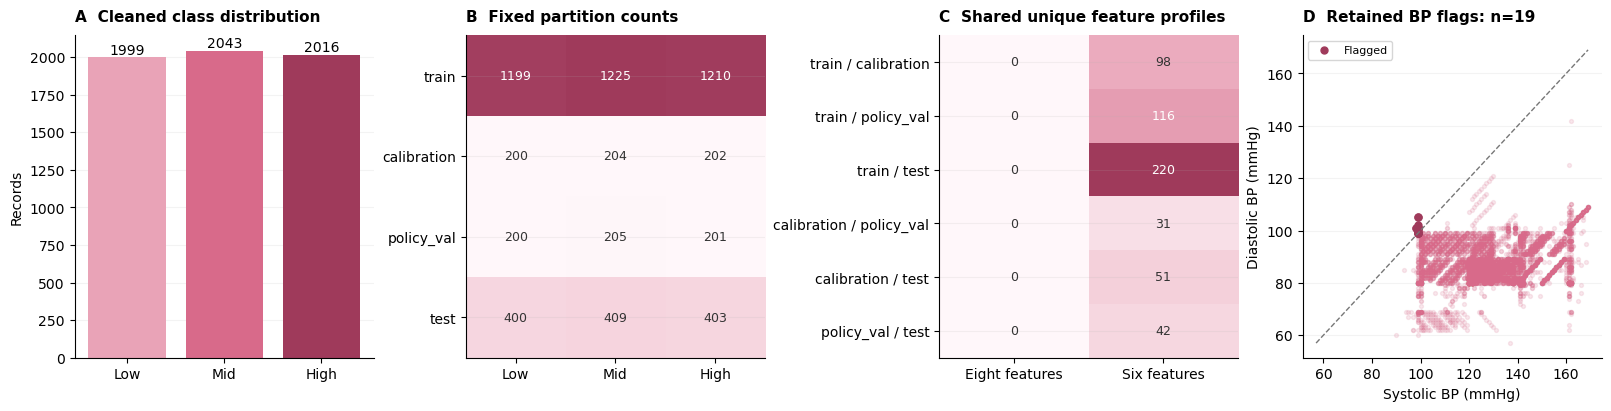

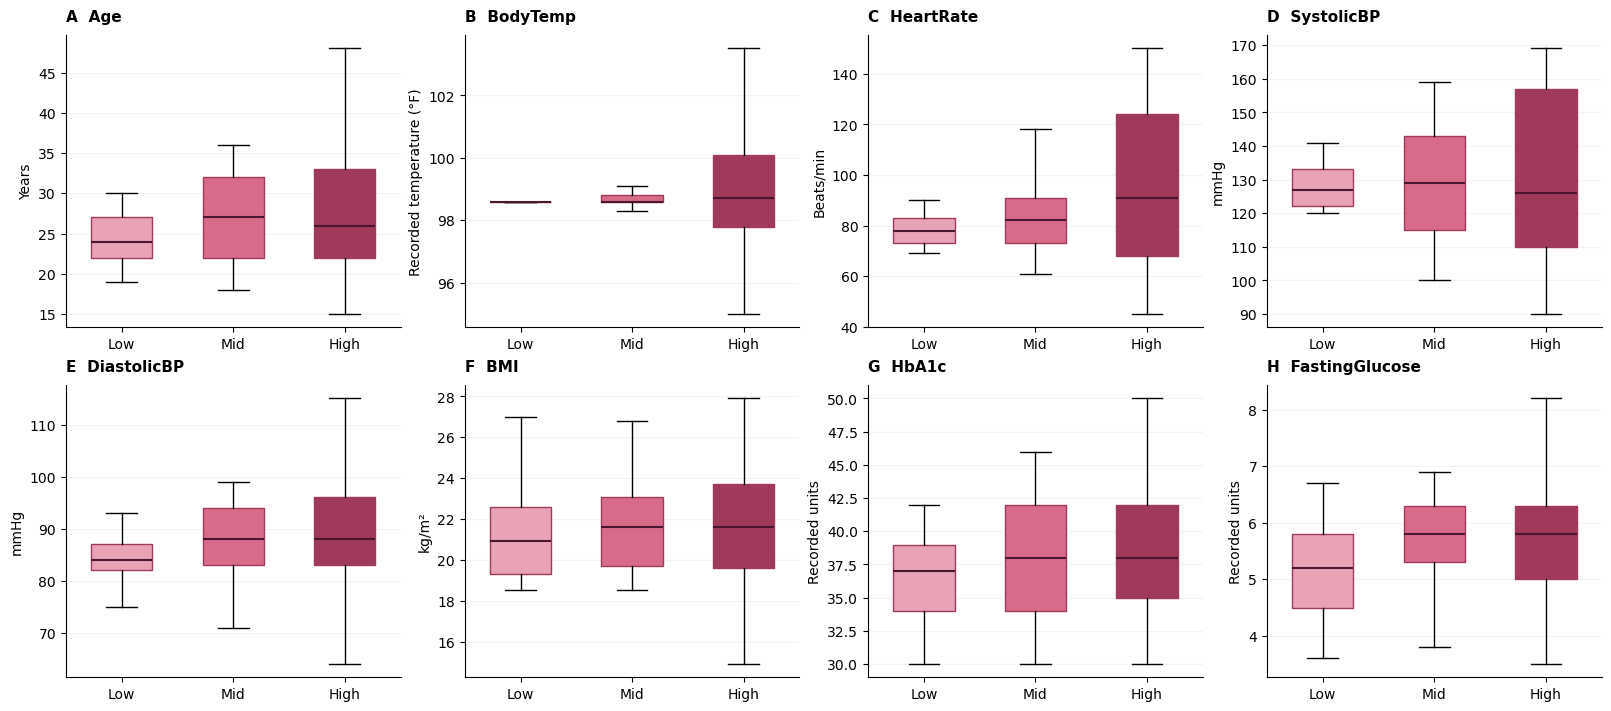

,Feature,Low,Mid,High
0,Age,"24.00 [22.00, 27.00]","27.00 [22.00, 32.00]","26.00 [22.00, 33.00]"
1,BodyTemp,"98.60 [98.60, 98.60]","98.60 [98.60, 98.80]","98.70 [97.80, 100.10]"
2,HeartRate,"78.00 [73.00, 83.00]","82.00 [73.00, 91.00]","91.00 [68.00, 124.00]"
3,SystolicBP,"127.00 [122.00, 133.00]","129.00 [115.00, 143.00]","126.00 [110.00, 157.00]"
4,DiastolicBP,"84.00 [82.00, 87.00]","88.00 [83.00, 94.00]","88.00 [83.00, 96.00]"
5,BMI,"20.90 [19.30, 22.60]","21.60 [19.70, 23.10]","21.60 [19.60, 23.70]"
6,HbA1c,"37.00 [34.00, 39.00]","38.00 [34.00, 42.00]","38.00 [35.00, 42.00]"
7,FastingGlucose,"5.20 [4.50, 5.80]","5.80 [5.30, 6.30]","5.80 [5.00, 6.30]"


,Feature,Low,Mid,High
0,Age,"24.00 [22.00, 27.00]","27.00 [22.00, 32.00]","26.00 [22.00, 33.00]"
1,BodyTemp,"98.60 [98.60, 98.60]","98.60 [98.60, 98.80]","98.70 [97.80, 100.10]"
2,HeartRate,"78.00 [73.00, 83.00]","82.00 [73.00, 91.00]","91.00 [68.00, 124.00]"
3,SystolicBP,"127.00 [122.00, 133.00]","129.00 [115.00, 143.00]","126.00 [110.00, 157.00]"
4,DiastolicBP,"84.00 [82.00, 87.00]","88.00 [83.00, 94.00]","88.00 [83.00, 96.00]"
5,BMI,"20.90 [19.30, 22.60]","21.60 [19.70, 23.10]","21.60 [19.60, 23.70]"
6,HbA1c,"37.00 [34.00, 39.00]","38.00 [34.00, 42.00]","38.00 [35.00, 42.00]"
7,FastingGlucose,"5.20 [4.50, 5.80]","5.80 [5.30, 6.30]","5.80 [5.00, 6.30]"


In [39]:
# FIGURE AUDIT: 4 panel liên quan chất lượng và phân chia dữ liệu.
fig, ax = plt.subplots(
    1, 4,
    figsize=(16, 4),
    squeeze=False,
    constrained_layout=True
)

# Giữ các lệnh ax[0,0], ax[0,1], ax[1,0], ax[1,1] bên dưới.
ax = ax.reshape(2, 2)

class_counts = all_data.RiskLevel.value_counts().reindex(LABELS)
ax[0, 0].bar(LABELS, class_counts, color=CLASS_COLORS)
ax[0, 0].set_ylabel("Records")
title(ax[0, 0], "A", "Cleaned class distribution")

for i, value in enumerate(class_counts):
    ax[0, 0].text(i, value + 20, str(value), ha="center")

split_counts = pd.crosstab(
    all_data.Split, all_data.RiskLevel
).reindex(index=SPLIT_NAMES, columns=LABELS)

heatmap(
    ax[0, 1], split_counts.to_numpy(),
    LABELS, SPLIT_NAMES
)
title(ax[0, 1], "B", "Fixed partition counts")

pair_names = (
    overlap.Partition_A + " / " + overlap.Partition_B
).tolist()

heatmap(
    ax[1, 0],
    overlap[
        ["Exact_8_Unique_Profiles", "Basic_6_Unique_Profiles"]
    ].to_numpy(),
    ["Eight features", "Six features"], pair_names
)
title(ax[1, 0], "C", "Shared unique feature profiles")

ax[1, 1].scatter(
    all_data.SystolicBP, all_data.DiastolicBP,
    s=8, alpha=0.15, color=PINK_MID, rasterized=True
)
ax[1, 1].scatter(
    bp_records.SystolicBP, bp_records.DiastolicBP,
    s=25, color=PINK_DARK, label="Flagged"
)

bp_min = min(
    all_data.SystolicBP.min(), all_data.DiastolicBP.min()
)
bp_max = max(
    all_data.SystolicBP.max(), all_data.DiastolicBP.max()
)

ax[1, 1].plot(
    [bp_min, bp_max], [bp_min, bp_max],
    "--", color=GRAY, linewidth=1
)
ax[1, 1].set(
    xlabel="Systolic BP (mmHg)",
    ylabel="Diastolic BP (mmHg)"
)
ax[1, 1].legend()
title(ax[1, 1], "D", f"Retained BP flags: n={len(bp_records)}")

savefig(fig, "FA_data_audit")


# FIGURE 2: cả tám predictor trong một khung.
units = {
    "Age": "Years",
    "BodyTemp": "Recorded temperature (°F)",
    "HeartRate": "Beats/min",
    "SystolicBP": "mmHg",
    "DiastolicBP": "mmHg",
    "BMI": "kg/m²",
    "HbA1c": "Recorded units",
    "FastingGlucose": "Recorded units",
}

fig, ax = plt.subplots(
    2, 4,
    figsize=(16, 7),
    squeeze=False,
    constrained_layout=True
)

for i, feature in enumerate(FULL):
    a = ax.flat[i]

    values = [
        all_data.loc[all_data.RiskLevel == label, feature]
        for label in LABELS
    ]

    boxes = a.boxplot(
        values, patch_artist=True,
        showfliers=False, widths=0.55,
        medianprops={"color": "#4B1730", "linewidth": 1.5}
    )

    for patch, color in zip(boxes["boxes"], CLASS_COLORS):
        patch.set_facecolor(color)
        patch.set_edgecolor(PINK_DARK)

    a.set_xticks([1, 2, 3])
    a.set_xticklabels(LABELS)
    a.set_ylabel(units[feature])
    title(a, chr(65+i), feature)

savefig(fig, "F02_predictor_distributions")

eda_rows = []

for feature in FULL:
    row = {"Feature": feature}
    for label in LABELS:
        values = all_data.loc[
            all_data.RiskLevel == label, feature
        ]
        q1, median, q3 = values.quantile([0.25, 0.5, 0.75])
        row[label] = f"{median:.2f} [{q1:.2f}, {q3:.2f}]"
    eda_rows.append(row)

table(pd.DataFrame(eda_rows), "eda_median_iqr")

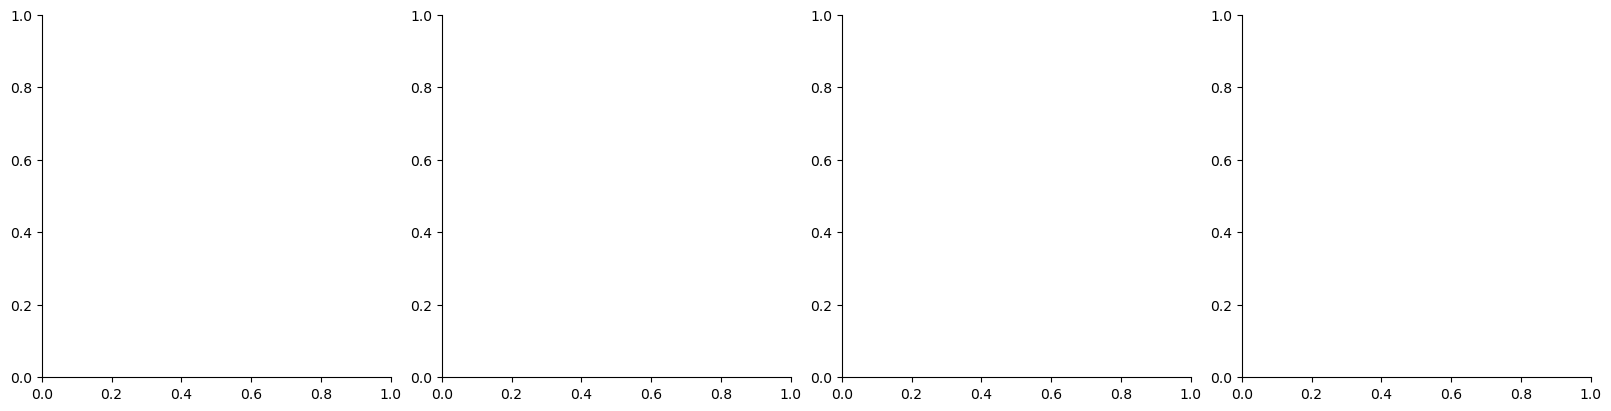

Panel A: error bars là SD giữa CV folds. Panel D: khoảng Wilson trên test; hai loại này khác nhau.


In [36]:
benchmark_dir = BASE / "section_4_1_verified"

tuning_path = benchmark_dir / "table_5_hyperparameter_tuning.csv"
test_path = benchmark_dir / "table_6_final_test.csv"

for path in [tuning_path, test_path]:
    assert path.is_file(), (
        f"Thiếu {path}. Lấy CSV từ output 4.1 đã chốt; "
        "không chạy tuning mới chỉ để khôi phục bảng."
    )

cv_results = pd.read_csv(tuning_path)
test_results = pd.read_csv(test_path)

assert {
    "Model", "Default_Macro_F1", "Tuned_Macro_F1", "Tuned_SD"
}.issubset(cv_results.columns)

assert {"Model", "Macro_F1"}.issubset(test_results.columns)

model_order = ["LR", "DT", "RF", "SVM", "XGB"]

assert cv_results.Model.is_unique
assert test_results.Model.is_unique
assert set(model_order).issubset(cv_results.Model)
assert set(model_order).issubset(test_results.Model)

cv_results = (
    cv_results.set_index("Model").loc[model_order].reset_index()
)
test_results = (
    test_results.set_index("Model").loc[model_order].reset_index()
)

assert np.isclose(
    test_results.loc[
        test_results.Model == "XGB", "Macro_F1"
    ].iloc[0],
    metrics(y, pred_full)["Macro_F1"],
    atol=1e-5, rtol=0
), "Bảng benchmark và Full model không cùng baseline."

# Tạo trực tiếp 1 hàng × 4 cột.
fig, axes = plt.subplots(
    nrows=1,
    ncols=4,
    figsize=(16, 4),
    constrained_layout=True
)

a, b, c, d = axes

# Kiểm tra chính figure bệnh nhân này.
assert all(
    axis.get_subplotspec().get_gridspec().nrows == 1
    and axis.get_subplotspec().get_gridspec().ncols == 4
    for axis in axes
), "Figure chưa có bố cục 1×4."
x = np.arange(len(model_order))

ax[0, 0].bar(
    x-0.18, cv_results.Default_Macro_F1,
    width=0.36, color=PINK_LIGHT, label="Default"
)
ax[0, 0].bar(
    x+0.18, cv_results.Tuned_Macro_F1,
    width=0.36, yerr=cv_results.Tuned_SD,
    capsize=3, color=PINK_DARK, label="Tuned ± fold SD"
)
ax[0, 0].set_xticks(x)
ax[0, 0].set_xticklabels(model_order)
ax[0, 0].set(ylabel="Macro-F1", ylim=(0, 1.06))
ax[0, 0].legend()
title(ax[0, 0], "A", "Training cross-validation")

ax[0, 1].bar(
    test_results.Model, test_results.Macro_F1,
    color=[
        PINK_DARK if name == "XGB" else PINK_LIGHT
        for name in test_results.Model
    ]
)
ax[0, 1].set(ylabel="Macro-F1", ylim=(0, 1.06))
title(ax[0, 1], "B", "Held-out test performance")

heatmap(ax[1, 0], actual_cm, LABELS, LABELS)
ax[1, 0].set(xlabel="Predicted class", ylabel="Actual class")
title(ax[1, 0], "C", "Full XGBoost confusion counts")

ax[1, 1].bar(
    basic_full.Model, basic_full.High_Recall,
    color=[PINK_LIGHT, PINK_DARK]
)
ax[1, 1].errorbar(
    basic_full.Model, basic_full.High_Recall,
    yerr=np.vstack([
        basic_full.High_Recall - basic_full.Recall_Lower,
        basic_full.Recall_Upper - basic_full.High_Recall
    ]),
    fmt="none", ecolor="#333333", capsize=4
)
ax[1, 1].set(ylabel="High-risk recall", ylim=(0, 1.06))
title(ax[1, 1], "D", "Basic vs Full: 95% Wilson intervals")

savefig(fig, "F03_model_benchmark")

table(cv_results, "benchmark_cv", show=False)
table(test_results, "benchmark_test", show=False)

print(
    "Panel A: error bars là SD giữa CV folds. "
    "Panel D: khoảng Wilson trên test; hai loại này khác nhau."
)

,Split,Model,Stage,Brier,LogLoss,High_ECE
0,policy_val,basic,Raw,0.13768,0.25469,0.03125
1,policy_val,basic,Calibrated,0.14032,0.25773,0.03484
2,policy_val,full,Raw,0.02508,0.05870,0.01024
3,policy_val,full,Calibrated,0.02506,0.05858,0.01021
4,test,basic,Raw,0.13991,0.25140,0.03510
5,test,basic,Calibrated,0.14103,0.24722,0.03403
6,test,full,Raw,0.00968,0.02461,0.00730
7,test,full,Calibrated,0.00969,0.02472,0.00744


,Coverage,Retained,Errors,Error_Rate,Lower,Upper
0,10,122,0,0.00000,0.0000,0.03053
1,20,243,0,0.00000,0.0000,0.01556
2,30,364,0,0.00000,0.0000,0.01044
3,40,485,0,0.00000,0.0000,0.00786
4,50,606,0,0.00000,0.0000,0.00630
5,60,728,0,0.00000,0.0000,0.00525
6,70,849,0,0.00000,0.0000,0.00450
7,80,970,0,0.00000,0.0000,0.00394
8,90,1091,2,0.00183,0.0005,0.00666
9,100,1212,7,0.00578,0.0028,0.01187


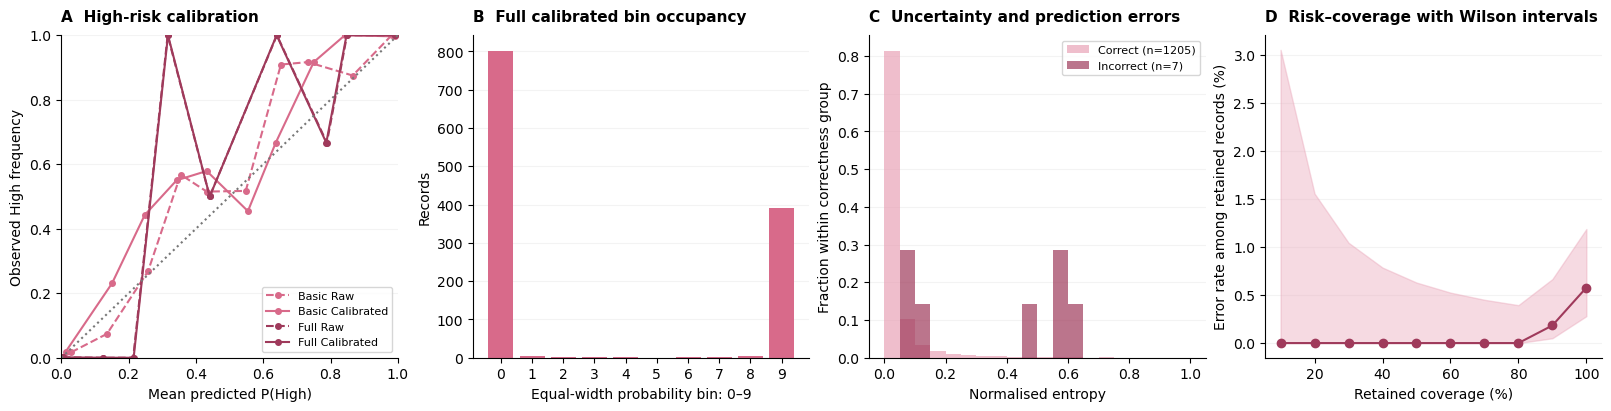

Mean entropy, correct: 0.0386386135680059
Mean entropy, incorrect: 0.3632269671846809


In [43]:
def calibration_bins(actual_high, predicted_high, bins=10):
    actual_high = np.asarray(actual_high, dtype=int)
    predicted_high = np.asarray(predicted_high, dtype=float)

    bin_ids = np.minimum(
        (predicted_high * bins).astype(int), bins-1
    )

    rows = []
    for i in range(bins):
        mask = bin_ids == i
        count = int(mask.sum())
        positives = int(actual_high[mask].sum())

        rows.append({
            "Bin": i,
            "N": count,
            "Mean_Predicted": (
                predicted_high[mask].mean() if count else np.nan
            ),
            "Observed": positives/count if count else np.nan,
        })

    return pd.DataFrame(rows)


def probability_metrics(y_true, p):
    bins = calibration_bins(y_true == 2, p[:, 2])
    ece = (
        bins.N / len(y_true)
        * (bins.Mean_Predicted - bins.Observed).abs()
    ).sum()

    return {
        "Brier": np.mean(
            np.sum((p - np.eye(3)[y_true])**2, axis=1)
        ),
        "LogLoss": log_loss(y_true, p, labels=[0, 1, 2]),
        "High_ECE": ece,
    }


reliability_rows = []

for split in ["policy_val", "test"]:
    ys = data[split].RiskLevel.map(LABEL_MAP).to_numpy()

    for model_name in ["basic", "full"]:
        for stage, p in [
            ("Raw", raw_probs[model_name, split]),
            ("Calibrated", probs[model_name, split]),
        ]:
            reliability_rows.append({
                "Split": split,
                "Model": model_name,
                "Stage": stage,
                **probability_metrics(ys, p)
            })

reliability_results = table(
    pd.DataFrame(reliability_rows),
    "reliability_metrics"
)

h = entropy(pf)
correct = pred_full == y

# Entropy thấp đứng trước; tie-break bằng row_id.
low_entropy_order = rank_desc(-h, ids)
risk_rows = []

for coverage in range(10, 101, 10):
    retained = int(np.ceil(len(y) * coverage / 100))
    ix = low_entropy_order[:retained]
    errors = int(np.sum(pred_full[ix] != y[ix]))
    lower, upper = wilson(errors, retained)

    risk_rows.append({
        "Coverage": coverage,
        "Retained": retained,
        "Errors": errors,
        "Error_Rate": errors / retained,
        "Lower": lower,
        "Upper": upper,
    })

risk_coverage = table(
    pd.DataFrame(risk_rows), "risk_coverage"
)

fig, ax = plt.subplots(
    1, 4,
    figsize=(16, 4),
    squeeze=False,
    constrained_layout=True
)

ax = ax.reshape(2, 2)

for model_name, color in [
    ("basic", PINK_MID), ("full", PINK_DARK)
]:
    for stage, p, style in [
        ("Raw", raw_probs[model_name, "test"], "--"),
        ("Calibrated", probs[model_name, "test"], "-"),
    ]:
        bins = calibration_bins(y == 2, p[:, 2])
        occupied = bins[bins.N > 0]

        ax[0, 0].plot(
            occupied.Mean_Predicted, occupied.Observed,
            style, marker="o", markersize=4,
            color=color, label=f"{model_name.title()} {stage}"
        )

ax[0, 0].plot([0, 1], [0, 1], ":", color=GRAY)
ax[0, 0].set(
    xlabel="Mean predicted P(High)",
    ylabel="Observed High frequency",
    xlim=(0, 1), ylim=(0, 1)
)
ax[0, 0].legend()
title(ax[0, 0], "A", "High-risk calibration")

bins = calibration_bins(y == 2, pf[:, 2])
ax[0, 1].bar(bins.Bin, bins.N, color=PINK_MID)
ax[0, 1].set_xticks(range(10))
ax[0, 1].set(
    xlabel="Equal-width probability bin: 0–9",
    ylabel="Records"
)
title(ax[0, 1], "B", "Full calibrated bin occupancy")

for mask, color, label in [
    (correct, PINK_LIGHT, "Correct"),
    (~correct, PINK_DARK, "Incorrect"),
]:
    if mask.any():
        ax[1, 0].hist(
            h[mask], bins=np.linspace(0, 1, 21),
            weights=np.ones(mask.sum()) / mask.sum(),
            color=color, alpha=0.7,
            label=f"{label} (n={mask.sum()})"
        )

ax[1, 0].set(
    xlabel="Normalised entropy",
    ylabel="Fraction within correctness group"
)
ax[1, 0].legend()
title(ax[1, 0], "C", "Uncertainty and prediction errors")

ax[1, 1].plot(
    risk_coverage.Coverage,
    risk_coverage.Error_Rate * 100,
    "o-", color=PINK_DARK
)
ax[1, 1].fill_between(
    risk_coverage.Coverage.to_numpy(),
    risk_coverage.Lower.to_numpy() * 100,
    risk_coverage.Upper.to_numpy() * 100,
    color=PINK_LIGHT, alpha=0.4
)
ax[1, 1].set(
    xlabel="Retained coverage (%)",
    ylabel="Error rate among retained records (%)"
)
title(ax[1, 1], "D", "Risk–coverage with Wilson intervals")

savefig(fig, "F04_reliability_uncertainty")

print(
    "Mean entropy, correct:",
    h[correct].mean() if correct.any() else np.nan
)
print(
    "Mean entropy, incorrect:",
    h[~correct].mean() if (~correct).any() else np.nan
)

,Policy,Lambda,N,Accuracy,Macro_F1,High_PPV,High_Recall,High_Specificity,TP,FP,FN,TN,Errors,High_to_Low,High_to_Mid,Undertriage,Overtriage,Severe_Errors,Ordinal_MAE,Cost_per_100
0,Argmax,0,606,0.98680,0.98680,0.99490,0.97015,0.99753,195,1,6,404,8,2,4,6,2,2,0.01650,4.29043
1,Ordinal,1,606,0.98515,0.98515,0.99487,0.96517,0.99753,194,1,7,404,9,2,5,7,2,2,0.01815,4.78548
2,Asym-2,2,606,0.98515,0.98516,0.98985,0.97015,0.99506,195,2,6,403,9,2,4,6,3,2,0.01815,4.45545
3,Asym-3,3,606,0.98680,0.98684,0.98990,0.97512,0.99506,196,2,5,403,8,1,4,5,3,1,0.01485,3.46535
4,Asym-5,5,606,0.98515,0.98519,0.98492,0.97512,0.99259,196,3,5,402,9,1,4,5,4,1,0.01650,3.63036
5,Asym-10,10,606,0.98350,0.98356,0.98492,0.97512,0.99259,196,3,5,402,10,1,4,5,5,1,0.01815,3.79538
6,Asym-20,20,606,0.98020,0.98033,0.97525,0.98010,0.98765,197,5,4,400,12,0,4,4,8,0,0.01980,3.30033


,Policy,N,Accuracy,Macro_F1,High_PPV,High_Recall,High_Specificity,TP,FP,FN,TN,Errors,High_to_Low,High_to_Mid,Undertriage,Overtriage,Severe_Errors,Ordinal_MAE,Cost_per_100
0,Argmax,1212,0.99422,0.99423,0.99750,0.99007,0.99876,399,1,4,808,7,1,3,6,1,1,0.0066,1.81518
1,Ordinal,1212,0.99422,0.99423,0.99750,0.99007,0.99876,399,1,4,808,7,1,3,6,1,1,0.0066,1.81518
2,Asym-20,1212,0.98020,0.98024,0.95943,0.99752,0.97899,402,17,1,792,24,0,1,3,21,0,0.0198,2.47525


,Difference_Argmax_Minus_Selected,Lower_95,Upper_95,Bootstrap_Repetitions
0,-0.66007,-1.89769,0.82508,2000


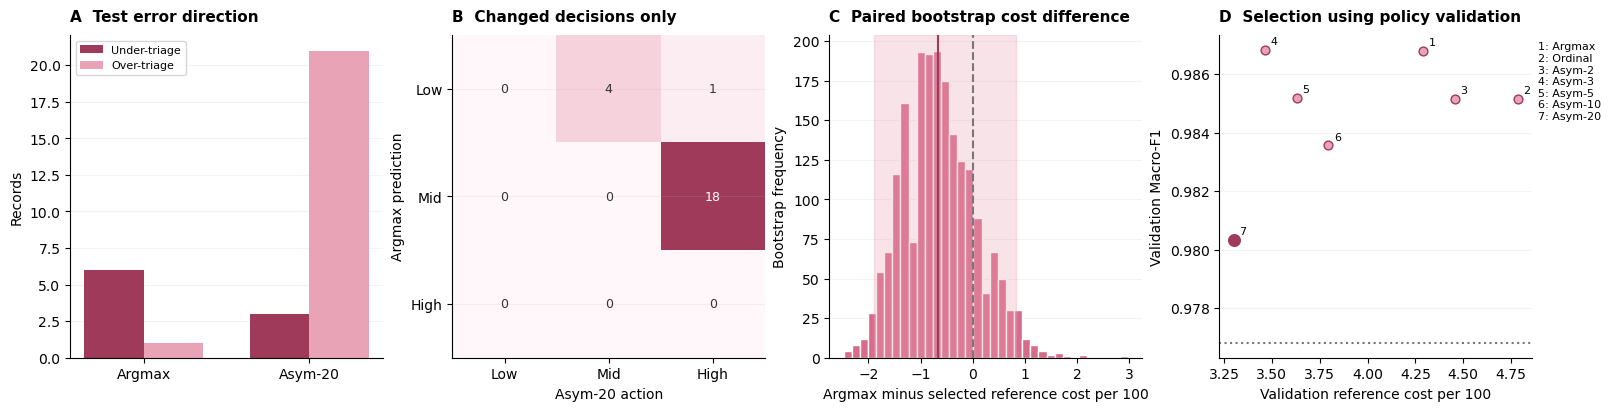

Selected: Asym-20
Changed decisions: 23
Corrected: 3
New errors: 20
Cost difference: -0.66007; 95% interval [-1.89769, 0.82508]


In [40]:
val = data["policy_val"]
yv = val.RiskLevel.map(LABEL_MAP).to_numpy()
iv = val.row_id.to_numpy()

bv = probs["basic", "policy_val"]
fv = probs["full", "policy_val"]

POLICIES = {
    "Argmax": None,
    "Ordinal": 1,
    "Asym-2": 2,
    "Asym-3": 3,
    "Asym-5": 5,
    "Asym-10": 10,
    "Asym-20": 20,
}

severity_validation = pd.DataFrame([
    {
        "Policy": name,
        "Lambda": 0 if lam is None else lam,
        **metrics(yv, decide(fv, lam))
    }
    for name, lam in POLICIES.items()
])

f1_floor = (
    severity_validation.loc[
        severity_validation.Policy == "Argmax", "Macro_F1"
    ].iloc[0] - 0.01
)

eligible = severity_validation.loc[
    severity_validation.Macro_F1 >= f1_floor - 1e-12
].sort_values(
    ["Cost_per_100", "High_Recall", "Macro_F1", "Lambda"],
    ascending=[True, False, False, True],
    kind="stable"
)

severity_name = eligible.iloc[0].Policy

assert severity_name == "Asym-20", (
    f"Validation chọn {severity_name}, khác report Asym-20. "
    "Kiểm tra provenance trước khi tiếp tục."
)

saved_policy_path = (
    BASE / "section_4_3/selected_severity_policy.json"
)
if saved_policy_path.exists():
    saved = json.loads(saved_policy_path.read_text())["selected_policy"]
    saved_name = saved["name"] if isinstance(saved, dict) else saved
    assert saved_name == severity_name

pred_severity = decide(pf, POLICIES[severity_name])

severity_test = pd.DataFrame([
    {
        "Policy": name,
        **metrics(y, decide(pf, POLICIES[name]))
    }
    for name in ["Argmax", "Ordinal", severity_name]
])

table(severity_validation, "severity_validation")
table(severity_test, "severity_test")

changed = pred_full != pred_severity

changed_cases = pd.DataFrame({
    "row_id": ids,
    "Actual": np.array(LABELS)[y],
    "Argmax": np.array(LABELS)[pred_full],
    "Selected": np.array(LABELS)[pred_severity],
    "Corrected": (pred_full != y) & (pred_severity == y),
    "New_Error": (pred_full == y) & (pred_severity != y),
})

table(
    changed_cases.loc[changed],
    "severity_changed_cases", show=False
)

reference_cost = cost_matrix(3)
paired_delta = (
    reference_cost[y, pred_full]
    - reference_cost[y, pred_severity]
)

rng = np.random.default_rng(SEED)
bootstrap = np.array([
    paired_delta[
        rng.integers(0, len(y), size=len(y))
    ].mean() * 100
    for _ in range(2000)
])

boot_lower, boot_upper = np.quantile(
    bootstrap, [0.025, 0.975]
)
cost_difference = paired_delta.mean() * 100

table(pd.DataFrame([{
    "Difference_Argmax_Minus_Selected": cost_difference,
    "Lower_95": boot_lower,
    "Upper_95": boot_upper,
    "Bootstrap_Repetitions": 2000,
}]), "severity_cost_interval")

table(
    pd.DataFrame({"Cost_Difference_per_100": bootstrap}),
    "severity_bootstrap_samples", show=False
)

fig, ax = plt.subplots(
    1, 4,
    figsize=(16, 4),
    squeeze=False,
    constrained_layout=True
)

ax = ax.reshape(2, 2)

comparison = severity_test[
    severity_test.Policy.isin(["Argmax", severity_name])
]
x = np.arange(len(comparison))

ax[0, 0].bar(
    x-0.18, comparison.Undertriage, width=0.36,
    color=PINK_DARK, label="Under-triage"
)
ax[0, 0].bar(
    x+0.18, comparison.Overtriage, width=0.36,
    color=PINK_LIGHT, label="Over-triage"
)
ax[0, 0].set_xticks(x)
ax[0, 0].set_xticklabels(comparison.Policy)
ax[0, 0].set_ylabel("Records")
ax[0, 0].legend()
title(ax[0, 0], "A", "Test error direction")

transition = np.zeros((3, 3), dtype=int)
np.add.at(
    transition,
    (pred_full[changed], pred_severity[changed]),
    1
)
heatmap(ax[0, 1], transition, LABELS, LABELS)
ax[0, 1].set(
    xlabel=f"{severity_name} action",
    ylabel="Argmax prediction"
)
title(ax[0, 1], "B", "Changed decisions only")

ax[1, 0].hist(
    bootstrap, bins=35,
    color=PINK_MID, edgecolor="white"
)
ax[1, 0].axvspan(
    boot_lower, boot_upper, color=PINK_LIGHT, alpha=0.3
)
ax[1, 0].axvline(0, color=GRAY, linestyle="--")
ax[1, 0].axvline(cost_difference, color=PINK_DARK)
ax[1, 0].set(
    xlabel="Argmax minus selected reference cost per 100",
    ylabel="Bootstrap frequency"
)
title(ax[1, 0], "C", "Paired bootstrap cost difference")

# Dùng số thứ tự + legend để nhãn không chồng lên nhau.
for i, row in severity_validation.reset_index(drop=True).iterrows():
    selected = row.Policy == severity_name
    ax[1, 1].scatter(
        row.Cost_per_100, row.Macro_F1,
        color=PINK_DARK if selected else PINK_LIGHT,
        edgecolor=PINK_DARK, s=70 if selected else 40
    )
    ax[1, 1].annotate(
        str(i+1), (row.Cost_per_100, row.Macro_F1),
        xytext=(4, 4), textcoords="offset points", fontsize=8
    )

key = "\n".join(
    f"{i+1}: {name}"
    for i, name in enumerate(severity_validation.Policy)
)
ax[1, 1].text(
    1.02, 0.98, key,
    transform=ax[1, 1].transAxes,
    va="top", fontsize=8
)
ax[1, 1].axhline(f1_floor, color=GRAY, linestyle=":")
ax[1, 1].set(
    xlabel="Validation reference cost per 100",
    ylabel="Validation Macro-F1"
)
title(ax[1, 1], "D", "Selection using policy validation")

savefig(fig, "F06_severity_tradeoffs")

print("Selected:", severity_name)
print("Changed decisions:", changed.sum())
print("Corrected:", changed_cases.loc[changed, "Corrected"].sum())
print("New errors:", changed_cases.loc[changed, "New_Error"].sum())
print(
    f"Cost difference: {cost_difference:.5f}; "
    f"95% interval [{boot_lower:.5f}, {boot_upper:.5f}]"
)

,Strategy,Macro_F1,High_Recall,Ordinal_MAE
4,Uncertainty,0.98063,0.96393,0.02517
0,Hybrid-25,0.97528,0.95896,0.03300
1,Hybrid-50,0.96437,0.92786,0.04373
2,Hybrid-75,0.95481,0.91667,0.05363
3,Risk,0.95318,0.91542,0.05611


,Budget,Measured_Records,Additional_Values,Labels_Different_From_Full,Probability_Rows_Different_From_Full,N,Accuracy,Macro_F1,High_PPV,High_Recall,...,FN,TN,Errors,High_to_Low,High_to_Mid,Undertriage,Overtriage,Severe_Errors,Ordinal_MAE,Cost_per_100
0,0,0,0,124,1212,1212,0.89521,0.89385,0.94801,0.76923,...,93,792,127,11,82,110,17,11,0.11386,31.35314
1,20,242,484,27,970,1212,0.97360,0.97365,0.99743,0.96278,...,15,808,32,6,9,31,1,6,0.03135,9.24092
2,40,484,968,9,728,1212,0.98680,0.98681,0.99747,0.97767,...,9,808,16,3,6,15,1,3,0.01568,4.53795
3,60,727,1454,5,485,1212,0.99010,0.99010,0.99747,0.97767,...,9,808,12,3,6,11,1,3,0.01238,3.54785
4,80,969,1938,0,243,1212,0.99422,0.99423,0.99750,0.99007,...,4,808,7,1,3,6,1,1,0.00660,1.81518
5,100,1212,2424,0,0,1212,0.99422,0.99423,0.99750,0.99007,...,4,808,7,1,3,6,1,1,0.00660,1.81518


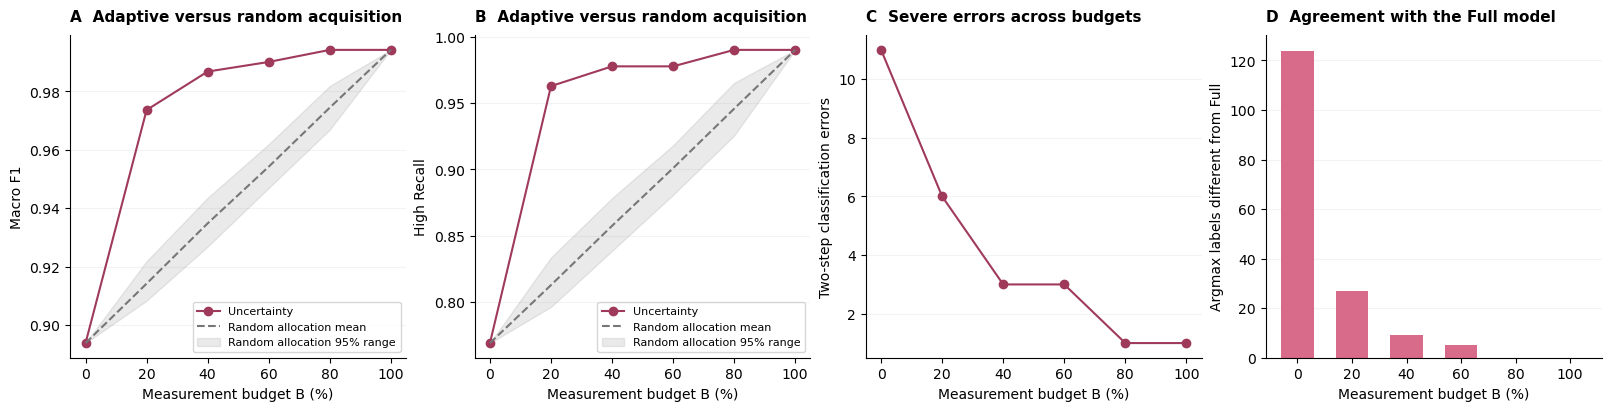

B=80% cần kiểm tra riêng:


,Budget,Measured_Records,Macro_F1,High_Recall,Labels_Different_From_Full,Probability_Rows_Different_From_Full
4,80,969,0.994234,0.990074,0,243


In [42]:
BUDGETS = [0, 20, 40, 60, 80, 100]

STRATEGIES = {
    "Risk": 1.0,
    "Uncertainty": 0.0,
    "Hybrid-25": 0.25,
    "Hybrid-50": 0.50,
    "Hybrid-75": 0.75,
}

adaptive_val_rows = []

for name, alpha in STRATEGIES.items():
    for budget in [20, 40, 60, 80]:
        p, measured = acquire(bv, fv, budget, alpha, iv)
        adaptive_val_rows.append({
            "Strategy": name,
            "Budget": budget,
            **metrics(yv, p.argmax(axis=1))
        })

adaptive_validation = pd.DataFrame(adaptive_val_rows)

adaptive_ranking = (
    adaptive_validation.groupby("Strategy")[
        ["Macro_F1", "High_Recall", "Ordinal_MAE"]
    ].mean().reset_index()
    .sort_values(
        ["Macro_F1", "High_Recall", "Ordinal_MAE", "Strategy"],
        ascending=[False, False, True, True],
        kind="stable"
    )
)

adaptive_name = adaptive_ranking.iloc[0].Strategy

assert adaptive_name == "Uncertainty", (
    f"Validation chọn {adaptive_name}, khác report. Dừng kiểm tra."
)

saved_adaptive_path = (
    BASE / "section_4_4/selected_adaptive_strategy.json"
)
if saved_adaptive_path.exists():
    saved = json.loads(
        saved_adaptive_path.read_text()
    )["selected_strategy"]
    saved_name = saved["name"] if isinstance(saved, dict) else saved
    assert saved_name == adaptive_name

table(adaptive_ranking, "adaptive_validation_ranking")
table(adaptive_validation, "adaptive_validation_detail", show=False)

mixed_probs = {}
adaptive_rows = []
random_rows = []

rng = np.random.default_rng(SEED)

for budget in BUDGETS:
    p, measured = acquire(
        pb, pf, budget, STRATEGIES[adaptive_name], ids
    )
    mixed_probs[budget] = p

    adaptive_rows.append({
        "Budget": budget,
        "Measured_Records": int(measured.sum()),
        "Additional_Values": int(measured.sum() * 2),
        "Labels_Different_From_Full": int(
            np.sum(p.argmax(axis=1) != pred_full)
        ),
        "Probability_Rows_Different_From_Full": int(
            np.sum(
                ~np.isclose(
                    p, pf, atol=1e-8, rtol=0
                ).all(axis=1)
            )
        ),
        **metrics(y, p.argmax(axis=1))
    })

    for repeat in range(200):
        selected = np.zeros(len(y), dtype=bool)
        selected[
            rng.choice(
                len(y), size=int(measured.sum()),
                replace=False
            )
        ] = True

        random_p = np.where(selected[:, None], pf, pb)
        m = metrics(y, random_p.argmax(axis=1))

        random_rows.append({
            "Budget": budget,
            "Repeat": repeat,
            "Macro_F1": m["Macro_F1"],
            "High_Recall": m["High_Recall"],
        })

adaptive_test = table(
    pd.DataFrame(adaptive_rows), "adaptive_test"
)
random_acquisition = pd.DataFrame(random_rows)
table(
    random_acquisition,
    "random_acquisition_repetitions", show=False
)

fig, ax = plt.subplots(
    1, 4,
    figsize=(16, 4),
    squeeze=False,
    constrained_layout=True
)

ax = ax.reshape(2, 2)

for column_index, metric in enumerate(["Macro_F1", "High_Recall"]):
    a = ax[0, column_index]

    grouped = random_acquisition.groupby("Budget")[metric]
    mean = grouped.mean().reindex(BUDGETS).to_numpy()
    lower = grouped.quantile(0.025).reindex(BUDGETS).to_numpy()
    upper = grouped.quantile(0.975).reindex(BUDGETS).to_numpy()

    a.plot(
        adaptive_test.Budget, adaptive_test[metric],
        "o-", color=PINK_DARK, label=adaptive_name
    )
    a.plot(
        BUDGETS, mean, "--", color=GRAY,
        label="Random allocation mean"
    )
    a.fill_between(
        BUDGETS, lower, upper, color=GRAY, alpha=0.15,
        label="Random allocation 95% range"
    )
    a.set(
        xlabel="Measurement budget B (%)",
        ylabel=metric.replace("_", " ")
    )
    a.legend()
    title(
        a, chr(65+column_index),
        "Adaptive versus random acquisition"
    )

ax[1, 0].plot(
    adaptive_test.Budget, adaptive_test.Severe_Errors,
    "o-", color=PINK_DARK
)
ax[1, 0].set(
    xlabel="Measurement budget B (%)",
    ylabel="Two-step classification errors"
)
title(ax[1, 0], "C", "Severe errors across budgets")

ax[1, 1].bar(
    adaptive_test.Budget,
    adaptive_test.Labels_Different_From_Full,
    width=12, color=PINK_MID
)
ax[1, 1].set(
    xlabel="Measurement budget B (%)",
    ylabel="Argmax labels different from Full"
)
title(ax[1, 1], "D", "Agreement with the Full model")

savefig(fig, "F07_adaptive_acquisition")

print("B=80% cần kiểm tra riêng:")
display(
    adaptive_test.loc[
        adaptive_test.Budget == 80,
        [
            "Budget", "Measured_Records", "Macro_F1",
            "High_Recall", "Labels_Different_From_Full",
            "Probability_Rows_Different_From_Full"
        ]
    ]
)

,Strategy,Recall_10,Recall_20,Recall_30,Recall_40,Recall_50,Mean_Recall
0,High probability,0.29851,0.60199,0.9005,0.99005,1.00000,0.75821
1,Expected severity,0.29851,0.60199,0.9005,0.98507,0.99005,0.75522


,Strategy,Capacity,Reviewed,Captured_High,Recall,Precision,Oracle_Recall,Oracle_Precision,Random_Recall,Random_Recall_Lower,Random_Recall_Upper,Random_Precision,Random_Precision_Lower,Random_Precision_Upper
0,High probability,10,121,121,0.30025,1.00000,0.30025,1.00000,0.09893,0.07692,0.12407,0.32950,0.25620,0.41322
1,Expected severity,10,121,121,0.30025,1.00000,0.30025,1.00000,0.09893,0.07692,0.12407,0.32950,0.25620,0.41322
2,High probability,20,242,242,0.60050,1.00000,0.60050,1.00000,0.19863,0.16625,0.22829,0.33077,0.27686,0.38017
3,Expected severity,20,242,242,0.60050,1.00000,0.60050,1.00000,0.19863,0.16625,0.22829,0.33077,0.27686,0.38017
4,High probability,30,363,363,0.90074,1.00000,0.90074,1.00000,0.29899,0.26055,0.33499,0.33193,0.28926,0.37190
5,Expected severity,30,363,363,0.90074,1.00000,0.90074,1.00000,0.29899,0.26055,0.33499,0.33193,0.28926,0.37190
6,High probability,40,484,402,0.99752,0.83058,1.00000,0.83264,0.40099,0.35980,0.44299,0.33388,0.29959,0.36885
7,Expected severity,40,484,401,0.99504,0.82851,1.00000,0.83264,0.40099,0.35980,0.44299,0.33388,0.29959,0.36885
8,High probability,50,606,403,1.00000,0.66502,1.00000,0.66502,0.50099,0.46402,0.53976,0.33317,0.30858,0.35895
9,Expected severity,50,606,402,0.99752,0.66337,1.00000,0.66502,0.50099,0.46402,0.53976,0.33317,0.30858,0.35895


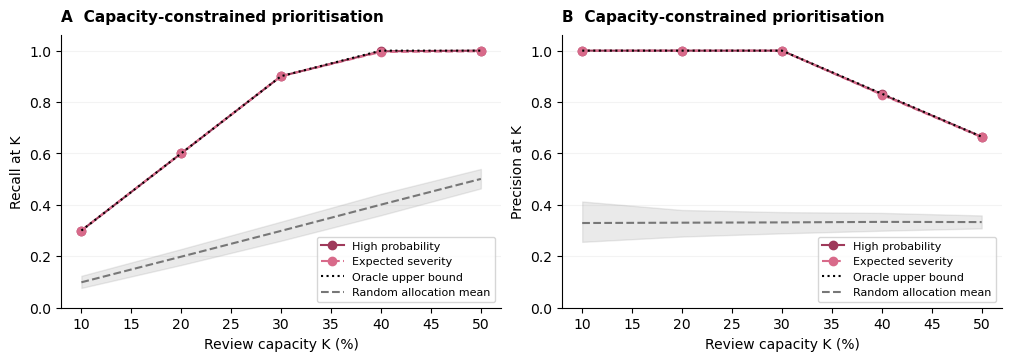

,Budget,Capacity,Reviewed,Captured_High,Recall,Precision,Oracle_Recall,Gap_to_Oracle
0,0,10,121,121,0.30025,1.00000,0.30025,0.00000
1,0,20,242,242,0.60050,1.00000,0.60050,0.00000
2,0,30,363,328,0.81390,0.90358,0.90074,0.08685
3,0,40,484,384,0.95285,0.79339,1.00000,0.04715
4,0,50,606,393,0.97519,0.64851,1.00000,0.02481
5,20,10,121,121,0.30025,1.00000,0.30025,0.00000
6,20,20,242,242,0.60050,1.00000,0.60050,0.00000
7,20,30,363,363,0.90074,1.00000,0.90074,0.00000
8,20,40,484,392,0.97270,0.80992,1.00000,0.02730
9,20,50,606,395,0.98015,0.65182,1.00000,0.01985


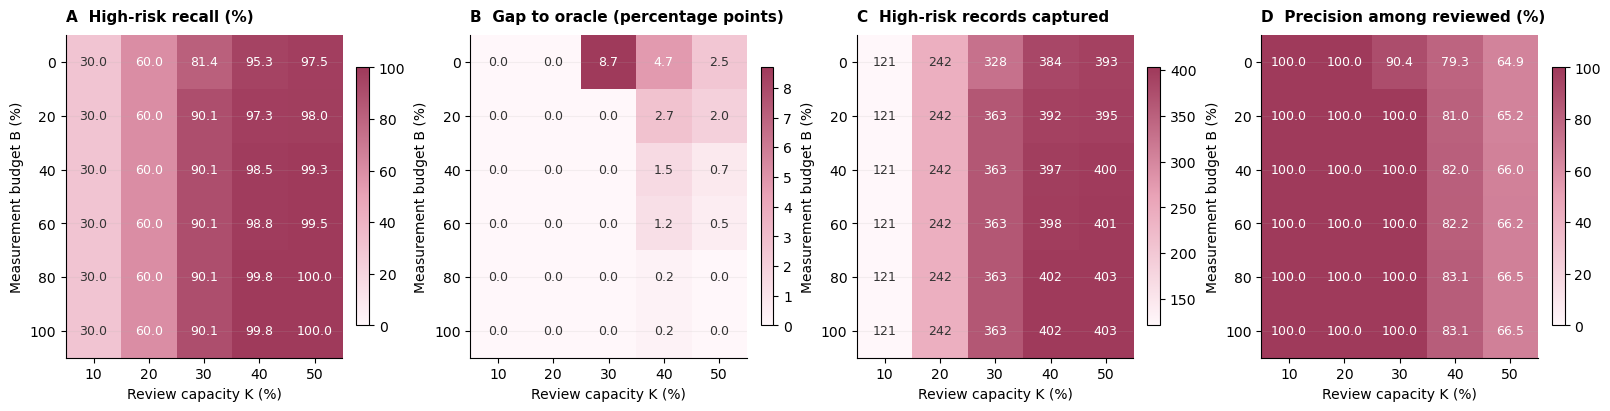

In [44]:
CAPACITIES = [10, 20, 30, 40, 50]


def ranking_score(p, strategy):
    if strategy == "High probability":
        return p[:, 2]
    if strategy == "Expected severity":
        return p[:, 1] + 2*p[:, 2]
    raise ValueError(strategy)


ranking_val_rows = []

for strategy in ["High probability", "Expected severity"]:
    row = {"Strategy": strategy}
    recalls = []

    for capacity in CAPACITIES:
        count = int(np.floor(len(yv) * capacity / 100))
        chosen = rank_desc(
            ranking_score(fv, strategy), iv
        )[:count]

        recall = np.sum(yv[chosen] == 2) / np.sum(yv == 2)
        row[f"Recall_{capacity}"] = recall
        recalls.append(recall)

    row["Mean_Recall"] = np.mean(recalls)
    ranking_val_rows.append(row)

ranking_validation = pd.DataFrame(
    ranking_val_rows
).sort_values(
    ["Mean_Recall", "Recall_20", "Recall_10", "Strategy"],
    ascending=[False, False, False, True],
    kind="stable"
)

ranking_name = ranking_validation.iloc[0].Strategy
assert ranking_name == "High probability", (
    "Ranking strategy khác report; cần kiểm tra provenance."
)

table(ranking_validation, "capacity_validation")

n_high = int(np.sum(y == 2))
assert n_high > 0

capacity_rows = []
rng = np.random.default_rng(SEED)

for capacity in CAPACITIES:
    count = int(np.floor(len(y) * capacity / 100))
    oracle_tp = min(count, n_high)

    random_tp = np.array([
        np.sum(
            y[rng.choice(len(y), size=count, replace=False)] == 2
        )
        for _ in range(500)
    ])

    for strategy in ["High probability", "Expected severity"]:
        chosen = rank_desc(
            ranking_score(pf, strategy), ids
        )[:count]
        tp = int(np.sum(y[chosen] == 2))

        capacity_rows.append({
            "Strategy": strategy,
            "Capacity": capacity,
            "Reviewed": count,
            "Captured_High": tp,
            "Recall": tp / n_high,
            "Precision": tp / count,
            "Oracle_Recall": oracle_tp / n_high,
            "Oracle_Precision": oracle_tp / count,
            "Random_Recall": random_tp.mean() / n_high,
            "Random_Recall_Lower": (
                np.quantile(random_tp, 0.025) / n_high
            ),
            "Random_Recall_Upper": (
                np.quantile(random_tp, 0.975) / n_high
            ),
            "Random_Precision": random_tp.mean() / count,
            "Random_Precision_Lower": (
                np.quantile(random_tp, 0.025) / count
            ),
            "Random_Precision_Upper": (
                np.quantile(random_tp, 0.975) / count
            ),
        })

capacity_test = table(
    pd.DataFrame(capacity_rows), "capacity_test"
)

fig, ax = plt.subplots(
    1, 2,
    figsize=(10, 3.5),
    squeeze=False,
    constrained_layout=True
)

for strategy, color, style in [
    ("High probability", PINK_DARK, "-"),
    ("Expected severity", PINK_MID, "--"),
]:
    group = capacity_test[
        capacity_test.Strategy == strategy
    ].sort_values("Capacity")

    for i, metric in enumerate(["Recall", "Precision"]):
        ax[0, i].plot(
            group.Capacity, group[metric],
            marker="o", linestyle=style,
            color=color, label=strategy
        )

reference = capacity_test[
    capacity_test.Strategy == "High probability"
].sort_values("Capacity")

for i, metric in enumerate(["Recall", "Precision"]):
    a = ax[0, i]
    a.plot(
        reference.Capacity, reference[f"Oracle_{metric}"],
        ":", color="black", label="Oracle upper bound"
    )
    a.plot(
        reference.Capacity, reference[f"Random_{metric}"],
        "--", color=GRAY, label="Random allocation mean"
    )
    a.fill_between(
        reference.Capacity.to_numpy(),
        reference[f"Random_{metric}_Lower"].to_numpy(),
        reference[f"Random_{metric}_Upper"].to_numpy(),
        color=GRAY, alpha=0.15
    )
    a.set(
        xlabel="Review capacity K (%)",
        ylabel=f"{metric} at K",
        ylim=(0, 1.06)
    )
    a.legend()
    title(a, chr(65+i), "Capacity-constrained prioritisation")

savefig(fig, "F08_capacity_prioritisation")


joint_rows = []

for budget in BUDGETS:
    p = mixed_probs[budget]

    for capacity in CAPACITIES:
        count = int(np.floor(len(y) * capacity / 100))
        chosen = rank_desc(
            ranking_score(p, ranking_name), ids
        )[:count]

        captured = int(np.sum(y[chosen] == 2))
        oracle_recall = min(count, n_high) / n_high
        recall = captured / n_high

        joint_rows.append({
            "Budget": budget,
            "Capacity": capacity,
            "Reviewed": count,
            "Captured_High": captured,
            "Recall": recall,
            "Precision": captured / count,
            "Oracle_Recall": oracle_recall,
            "Gap_to_Oracle": oracle_recall - recall,
        })

joint = table(pd.DataFrame(joint_rows), "joint_budget_capacity")
assert len(joint) == 30

fig, ax = plt.subplots(
    1, 4,
    figsize=(16, 4),
    squeeze=False,
    constrained_layout=True
)

ax = ax.reshape(2, 2)

specs = [
    ("Recall", "High-risk recall (%)", 100, ".1f", (0, 100)),
    ("Gap_to_Oracle", "Gap to oracle (percentage points)",
     100, ".1f", None),
    ("Captured_High", "High-risk records captured", 1, ".0f", None),
    ("Precision", "Precision among reviewed (%)",
     100, ".1f", (0, 100)),
]

for i, (column, heading, multiplier, fmt, limits) in enumerate(specs):
    a = ax.flat[i]
    matrix = joint.pivot(
        index="Budget", columns="Capacity", values=column
    ).reindex(index=BUDGETS, columns=CAPACITIES)

    im = heatmap(
        a, matrix.to_numpy() * multiplier,
        CAPACITIES, BUDGETS, fmt=fmt, limits=limits
    )
    a.set(
        xlabel="Review capacity K (%)",
        ylabel="Measurement budget B (%)"
    )
    title(a, chr(65+i), heading)
    fig.colorbar(im, ax=a, shrink=0.8)

savefig(fig, "F09_joint_resources")

In [ ]:
# Giữ bản metric gốc để kiểm tra.
bp_sensitivity_raw = bp_sensitivity.copy()

# Chỉ thay cách báo cáo cho subset chỉ chứa một lớp.
flagged_row = bp_sensitivity["Subset"].eq("Flagged BP only")

if (
    test_bp_flag.any()
    and np.unique(y[test_bp_flag]).size == 1
):
    bp_sensitivity.loc[flagged_row, "Macro_F1"] = np.nan

# Cập nhật bảng dùng cho report.
_ = table(
    bp_sensitivity,
    "bp_evaluation_sensitivity",
    show=False
)

display(
    bp_sensitivity[
        [
            "Subset", "N", "Accuracy", "Macro_F1",
            "High_Recall", "High_Specificity",
            "Errors", "High_to_Low"
        ]
    ].style.format(precision=5, na_rep="—")
)

,Subset,N,Accuracy,Macro_F1,High_Recall,High_Specificity,Errors,High_to_Low
0,All test,1212,0.99422,0.99423,0.99007,0.99876,7,1
1,Flagged BP only,2,1.00000,—,1.00000,—,0,0
2,Exclude flagged BP,1210,0.99421,0.99422,0.99002,0.99876,7,1


,row_id,RiskLevel,Age,BodyTemp,HeartRate,SystolicBP,DiastolicBP,BMI,HbA1c,FastingGlucose,p_Low,p_Mid,p_High,Argmax,Severity_Action,Entropy
1163,R005794,High,37,98.6,140,111,103,24.5,49,7.0,0.00000,0.00001,0.99999,High,High,0.00015
341,R001727,Mid,22,98.6,94,128,85,19.3,35,5.9,0.35033,0.61816,0.03151,Mid,Mid,0.70428
723,R003661,High,27,98.6,82,132,83,18.1,37,3.9,0.57036,0.00241,0.42723,Low,High,0.63545


,Feature,Mean_Absolute_SHAP
3,SystolicBP,0.11618
0,Age,0.06812
2,HeartRate,0.06476
6,HbA1c,0.03697
4,DiastolicBP,0.03619
7,FastingGlucose,0.03586
5,BMI,0.03209
1,BodyTemp,0.02399


,Feature,Value,SHAP
5,BMI,18.1,0.47851
3,SystolicBP,132.0,-0.07429
0,Age,27.0,-0.05575
7,FastingGlucose,3.9,-0.03860
4,DiastolicBP,83.0,-0.02929
2,HeartRate,82.0,-0.02285
1,BodyTemp,98.6,-0.02193
6,HbA1c,37.0,-0.00949


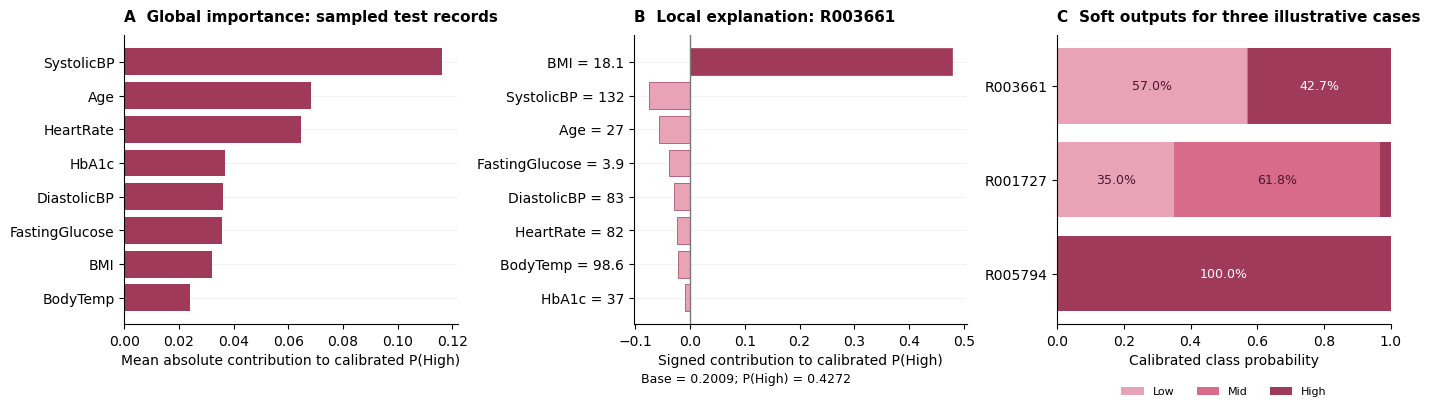

SHAP target: calibrated P(High)
Additivity residual: 2.220446049250313e-16
Đặc trưng đóng góp mạnh nhất cho ca R003661:


,Feature,Value,SHAP
5,BMI,18.1,0.478511
3,SystolicBP,132.0,-0.074286
0,Age,27.0,-0.055748
7,FastingGlucose,3.9,-0.038601


In [45]:
import shap

CASE_IDS = ["R005794", "R001727", "R003661"]

assert set(CASE_IDS).issubset(set(test.row_id)), (
    "Không tìm đủ ba row_id minh họa trong test."
)

case_indices = (
    test.reset_index()
    .set_index("row_id")
    .loc[CASE_IDS, "index"]
    .to_numpy(dtype=int)
)

case_table = test.loc[
    case_indices, ["row_id", "RiskLevel"] + FULL
].copy()

case_table[["p_Low", "p_Mid", "p_High"]] = pf[case_indices]
case_table["Argmax"] = np.array(LABELS)[pred_full[case_indices]]
case_table["Severity_Action"] = np.array(LABELS)[
    pred_severity[case_indices]
]
case_table["Entropy"] = h[case_indices]

table(case_table, "soft_output_cases")


def calibrated_high(x):
    frame = pd.DataFrame(
        np.asarray(x, dtype=float), columns=FULL
    )
    raw = normalise(models["full"].predict_proba(frame))
    return temperature_scale(
        raw, temperatures["full"]
    )[:, 2]


background = data["train"][FULL].sample(
    n=25, random_state=SEED
)
explanation_sample = test.sample(
    n=60, random_state=SEED
)

np.random.seed(SEED)

explainer = shap.Explainer(
    calibrated_high,
    masker=shap.maskers.Independent(background),
    algorithm="permutation",
    seed=SEED
)

global_shap = explainer(
    explanation_sample[FULL],
    max_evals=10 * (2*len(FULL) + 1)
)

local_case = test.loc[test.row_id == "R003661"]
assert len(local_case) == 1

local_shap = explainer(
    local_case[FULL],
    max_evals=50 * (2*len(FULL) + 1)
)

global_values = np.asarray(global_shap.values)
local_values = np.asarray(local_shap.values)[0]
local_base = float(
    np.asarray(local_shap.base_values).reshape(-1)[0]
)
local_probability = float(calibrated_high(local_case[FULL])[0])

assert global_values.shape == (60, len(FULL))
assert local_values.shape == (len(FULL),)

additivity_residual = abs(
    local_base + local_values.sum() - local_probability
)
assert additivity_residual < 1e-5, (
    "SHAP additivity check không đạt."
)

importance = pd.DataFrame({
    "Feature": FULL,
    "Mean_Absolute_SHAP": np.abs(global_values).mean(axis=0)
}).sort_values("Mean_Absolute_SHAP", ascending=False)

local_attribution = pd.DataFrame({
    "Feature": FULL,
    "Value": local_case[FULL].iloc[0].to_numpy(),
    "SHAP": local_values
}).sort_values("SHAP", key=np.abs, ascending=False)

table(importance, "shap_global_calibrated_high")
table(local_attribution, "shap_R003661_calibrated_high")

fig, (a, b, c) = plt.subplots(
    1, 3,
    figsize=(14, 4),
    constrained_layout=True
)

ordered = importance.sort_values("Mean_Absolute_SHAP")
a.barh(
    ordered.Feature, ordered.Mean_Absolute_SHAP,
    color=PINK_DARK
)
a.set_xlabel("Mean absolute contribution to calibrated P(High)")
title(a, "A", "Global importance: sampled test records")

ordered_local = local_attribution.iloc[::-1]
local_labels = [
    f"{feature} = {value:g}"
    for feature, value in zip(
        ordered_local.Feature, ordered_local.Value
    )
]

b.barh(
    local_labels, ordered_local.SHAP,
    color=[
        PINK_DARK if value >= 0 else PINK_LIGHT
        for value in ordered_local.SHAP
    ],
    edgecolor=PINK_DARK, linewidth=0.5
)
b.axvline(0, color=GRAY, linewidth=1)
b.set_xlabel("Signed contribution to calibrated P(High)")
title(b, "B", "Local explanation: R003661")

b.text(
    0.02, -0.20,
    f"Base = {local_base:.4f}; "
    f"P(High) = {local_probability:.4f}",
    transform=b.transAxes, fontsize=9
)

left = np.zeros(len(CASE_IDS))
case_p = pf[case_indices]

for j, label in enumerate(LABELS):
    c.barh(
        CASE_IDS, case_p[:, j], left=left,
        color=CLASS_COLORS[j], label=label
    )

    for i, value in enumerate(case_p[:, j]):
        if value >= 0.08:
            c.text(
                left[i] + value/2, i,
                f"{value:.1%}", ha="center", va="center",
                color="white" if j == 2 else "#4B1730",
                fontsize=9
            )

    left += case_p[:, j]

c.set(xlim=(0, 1), xlabel="Calibrated class probability")
c.legend(
    loc="upper center", bbox_to_anchor=(0.5, -0.18),
    ncol=3, frameon=False
)
title(c, "C", "Soft outputs for three illustrative cases")

savefig(fig, "F05_global_local_explanations")

shap_scope = {
    "Target": "calibrated P(High)",
    "Training_Background_Size": len(background),
    "Test_Explanation_Sample_Size": len(explanation_sample),
    "Global_Permutation_Cycles": 10,
    "Local_Permutation_Cycles": 50,
    "Local_Case": "R003661",
    "Local_Base": local_base,
    "Local_P_High": local_probability,
    "Additivity_Residual": additivity_residual,
}

(OUT / "shap_scope.json").write_text(
    json.dumps(shap_scope, indent=2)
)

print("SHAP target:", shap_scope["Target"])
print("Additivity residual:", additivity_residual)
print("Đặc trưng đóng góp mạnh nhất cho ca R003661:")
display(local_attribution.head(4))

In [ ]:
def latex_escape(value):
    replacements = {
        "\\": r"\textbackslash{}",
        "&": r"\&",
        "%": r"\%",
        "$": r"\$",
        "#": r"\#",
        "_": r"\_",
        "{": r"\{",
        "}": r"\}",
        "~": r"\textasciitilde{}",
        "^": r"\textasciicircum{}",
    }
    return "".join(replacements.get(ch, ch) for ch in str(value))


def export_tabular(df, filename, decimals=4):
    lines = [
        r"\begin{tabular}{" + "l" * len(df.columns) + "}",
        r"\toprule",
        " & ".join(latex_escape(c) for c in df.columns) + r" \\",
        r"\midrule",
    ]

    for values in df.itertuples(index=False, name=None):
        cells = []
        for value in values:
            if pd.isna(value):
                text = "--"
            elif isinstance(value, (float, np.floating)):
                text = f"{value:.{decimals}f}"
            elif isinstance(value, (int, np.integer)):
                text = str(int(value))
            else:
                text = str(value)

            cells.append(latex_escape(text))

        lines.append(" & ".join(cells) + r" \\")

    lines += [r"\bottomrule", r"\end{tabular}"]
    (TAB / f"{filename}.tex").write_text(
        "\n".join(lines), encoding="utf-8"
    )


# Bảng audit gọn: đủ sáu cặp.
audit_for_report = overlap[
    [
        "Partition_A", "Partition_B",
        "Exact_8_Unique_Profiles",
        "Basic_6_Unique_Profiles"
    ]
].rename(columns={
    "Partition_A": "Partition A",
    "Partition_B": "Partition B",
    "Exact_8_Unique_Profiles": "Eight-feature overlap",
    "Basic_6_Unique_Profiles": "Six-feature overlap",
})

export_tabular(audit_for_report, "audit_pairs")
export_tabular(
    bp_counts.reset_index(), "bp_flags"
)
export_tabular(
    bp_sensitivity[
        ["Subset", "N", "Macro_F1", "High_Recall",
         "High_to_Low", "Severe_Errors"]
    ],
    "bp_sensitivity"
)

# Calibration: mỗi model một hàng, before/after đứng cạnh nhau.
calibration_table = (
    reliability_results[
        reliability_results.Split == "test"
    ]
    .pivot(
        index="Model", columns="Stage",
        values=["Brier", "LogLoss", "High_ECE"]
    )
)
calibration_table.columns = [
    f"{metric} {stage}"
    for metric, stage in calibration_table.columns
]
export_tabular(
    calibration_table.reset_index(), "calibration_comparison"
)

export_tabular(
    severity_validation[
        ["Policy", "Macro_F1", "High_Recall", "Cost_per_100"]
    ],
    "severity_validation"
)
export_tabular(
    severity_test[
        ["Policy", "Macro_F1", "High_Recall",
         "Undertriage", "Overtriage",
         "High_to_Low", "Cost_per_100"]
    ],
    "severity_test"
)

# Hai bảng cùng một khối: hiệu năng và mức sử dụng tài nguyên.
export_tabular(
    adaptive_test[
        ["Budget", "Measured_Records", "Macro_F1",
         "High_Recall", "Severe_Errors"]
    ],
    "adaptive_performance"
)
export_tabular(
    adaptive_test[
        ["Budget", "Additional_Values",
         "Labels_Different_From_Full",
         "Probability_Rows_Different_From_Full"]
    ],
    "adaptive_agreement"
)

export_tabular(
    capacity_test[
        capacity_test.Strategy == ranking_name
    ][
        ["Capacity", "Reviewed", "Captured_High",
         "Recall", "Precision"]
    ],
    "capacity_selected"
)

export_tabular(
    case_table[
        ["row_id", "RiskLevel", "Argmax",
         "p_Low", "p_Mid", "p_High", "Severity_Action"]
    ],
    "soft_output_cases"
)

required_inputs = [
    BASE / "splits" / f"{split}.csv"
    for split in SPLIT_NAMES
] + [
    BASE / "train_cv_folds.csv",
    BASE / "models/basic_model.joblib",
    BASE / "models/full_model.joblib",
    BASE / "models/model_metadata.json",
    BASE / "section_4_2/temperatures.json",
]

versions = {}
for package in [
    "numpy", "pandas", "scikit-learn", "xgboost",
    "matplotlib", "shap", "joblib"
]:
    try:
        versions[package] = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        versions[package] = "not installed"

manifest = {
    "Python": sys.version,
    "Platform": platform.platform(),
    "Versions": versions,
    "Seed": SEED,
    "Primary_Model_Refitted": False,
    "Temperature_Refitted": False,
    "Severity": severity_name,
    "Acquisition": adaptive_name,
    "Ranking": ranking_name,
    "Input_SHA256": {
        str(path.relative_to(BASE)):
        hashlib.sha256(path.read_bytes()).hexdigest()
        for path in required_inputs
    },
}

(OUT / "run_manifest.json").write_text(
    json.dumps(manifest, indent=2)
)

expected_figures = [
    "FA_data_audit",
    "F02_predictor_distributions",
    "F03_model_benchmark",
    "F04_reliability_uncertainty",
    "F05_global_local_explanations",
    "F06_severity_tradeoffs",
    "F07_adaptive_acquisition",
    "F08_capacity_prioritisation",
    "F09_joint_resources",
]

for name in expected_figures:
    for extension in ["png", "pdf", "svg"]:
        path = FIG / f"{name}.{extension}"
        assert path.exists() and path.stat().st_size > 0, path

print("HOÀN TẤT")
print("Figures:", FIG)
print("Tables:", TAB)
print("Reproducibility:", OUT / "run_manifest.json")
print("Versions:")
display(pd.Series(versions, name="Version").to_frame())

HOÀN TẤT
Figures: /Users/hgianee/Downloads/Maternal health risk data 2/output/report_final_checks/figures
Tables: /Users/hgianee/Downloads/Maternal health risk data 2/output/report_final_checks/tables
Reproducibility: /Users/hgianee/Downloads/Maternal health risk data 2/output/report_final_checks/run_manifest.json
Versions:


,Version
numpy,2.1.3
pandas,2.3.3
scikit-learn,1.6.1
xgboost,3.4.1
matplotlib,3.10.0
shap,0.54.1
joblib,1.4.2


In [ ]:
# Giữ bản số liệu gốc để đối chiếu.
bp_sensitivity_original = bp_sensitivity.copy()

# Bản dùng để trình bày trong report.
bp_sensitivity_report = bp_sensitivity.copy()

flagged_only = (
    bp_sensitivity_report["Subset"] == "Flagged BP only"
)

bp_sensitivity_report.loc[
    flagged_only, "Macro_F1"
] = np.nan

# Không đổi phương pháp tính metric chung hay các kết quả khác.
table(
    bp_sensitivity_report,
    "bp_evaluation_sensitivity_report",
    show=False
)

export_tabular(
    bp_sensitivity_report[
        [
            "Subset", "N", "Accuracy", "Macro_F1",
            "High_Recall", "High_to_Low", "Severe_Errors"
        ]
    ],
    "bp_sensitivity"
)

display(
    bp_sensitivity_report[
        [
            "Subset", "N", "Accuracy", "Macro_F1",
            "High_Recall", "Errors"
        ]
    ].round(5)
)

print(
    "Report note: Macro-F1 is not reported for the flagged-only "
    "subset because it contains only two High-risk records. "
    "High-risk specificity is undefined because no non-High "
    "records are present."
)

,Subset,N,Accuracy,Macro_F1,High_Recall,Errors
0,All test,1212,0.99422,0.99423,0.99007,7
1,Flagged BP only,2,1.00000,NaN,1.00000,0
2,Exclude flagged BP,1210,0.99421,0.99422,0.99002,7


Report note: Macro-F1 is not reported for the flagged-only subset because it contains only two High-risk records. High-risk specificity is undefined because no non-High records are present.


In [ ]:
import textwrap
import numpy as np
import matplotlib.pyplot as plt


def panels(
    rows,
    cols,
    width=None,
    row_height=None,
    compact=True
):
    """
    4 biểu đồ -> 1 hàng, 4 cột.
    8 biểu đồ -> 2 hàng, 4 cột.

    Giữ cách truy cập ax[...] của code cũ.
    """
    total = rows * cols

    if compact:
        display_cols = min(4, total)
        display_rows = int(np.ceil(total / display_cols))
    else:
        display_rows = rows
        display_cols = cols

    figure_width = 12 if width is None else width
    height_per_row = 3.4 if row_height is None else row_height

    fig, physical_axes = plt.subplots(
        display_rows,
        display_cols,
        figsize=(
            figure_width,
            height_per_row * display_rows
        ),
        squeeze=False,
        constrained_layout=True
    )

    flat_axes = physical_axes.ravel()

    for unused_ax in flat_axes[total:]:
        unused_ax.set_visible(False)

    logical_axes = np.array(
        flat_axes[:total], dtype=object
    ).reshape(rows, cols)

    return fig, logical_axes


def title(ax, letter, text):
    heading = textwrap.fill(
        text,
        width=24,
        break_long_words=False,
        break_on_hyphens=False
    )

    ax.set_title(
        f"{letter}  {heading}",
        loc="left",
        fontweight="bold",
        fontsize=10,
        pad=10
    )

    xlabel = ax.get_xlabel()
    ylabel = ax.get_ylabel()

    if xlabel:
        ax.set_xlabel(
            textwrap.fill(
                xlabel,
                width=28,
                break_long_words=False,
                break_on_hyphens=False
            ),
            fontsize=9
        )

    if ylabel:
        ax.set_ylabel(
            textwrap.fill(
                ylabel,
                width=32,
                break_long_words=False,
                break_on_hyphens=False
            ),
            fontsize=9
        )

    ax.tick_params(labelsize=8.5)
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)


# Kiểm tra bố cục ngay khi chạy cell.
fig_check, axes_check = panels(2, 2)

for letter, a in zip("ABCD", axes_check.ravel()):
    a.text(
        0.5, 0.5,
        f"Panel {letter}",
        ha="center",
        va="center",
        fontsize=18
    )
    a.set_xticks([])
    a.set_yticks([])

assert all(
    a.get_subplotspec().rowspan.start == 0
    for a in axes_check.ravel()
), "Bốn panel chưa nằm cùng hàng."

plt.show()
plt.close(fig_check)

print("PASS: A – B – C – D nằm trên cùng một hàng.")
print("EDA tám biểu đồ: bốn trên, bốn dưới.")

Đã thiết lập bố cục ngang.
2×2 -> 1×4; EDA 4×2 -> 2×4.


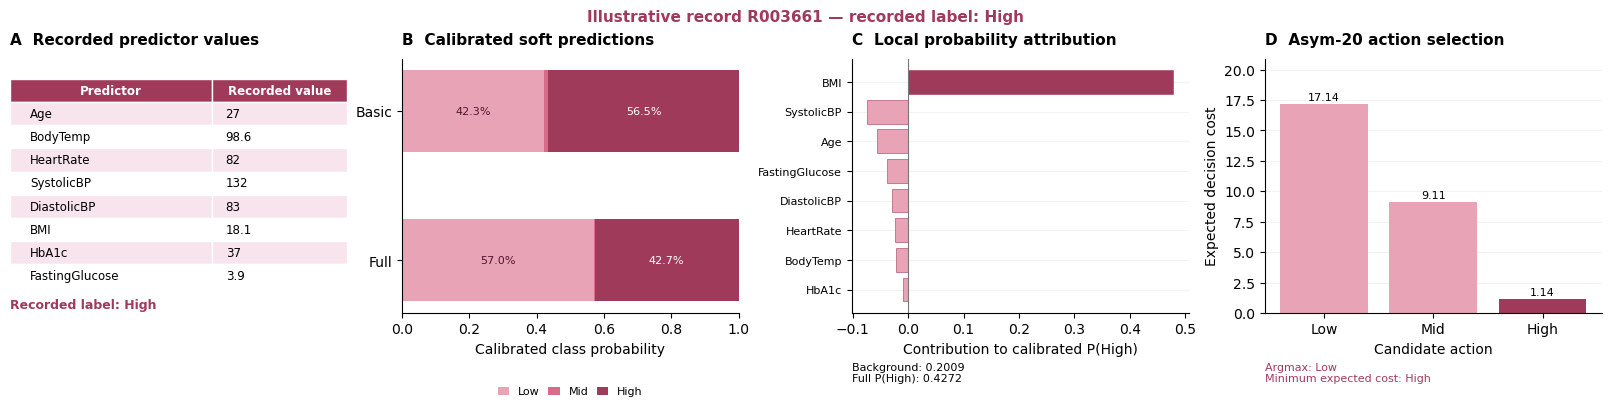

,Action,Expected_Decision_Cost_Lambda20,Selected
0,Low,17.13726,False
1,Mid,9.11488,False
2,High,1.14314,True


Patient figure completed: R003661
Full probabilities: {'Low': np.float64(0.570362609395017), 'Mid': np.float64(0.002411669124912804), 'High': np.float64(0.42722572148007015)}
SHAP residual: 2.220446049250313e-16


In [ ]:
CASE_ID = "R003661"

case_positions = np.flatnonzero(ids == CASE_ID)
assert len(case_positions) == 1
case_position = int(case_positions[0])

record = test.iloc[case_position]
case_basic = pb[case_position]
case_full = pf[case_position]

assert local_case.iloc[0]["row_id"] == CASE_ID
assert np.isclose(
    local_probability,
    case_full[2],
    atol=1e-8,
    rtol=0
)

# Expected cost của từng hành động theo decision matrix λ=20.
decision_lambda = 20
case_action_costs = (
    case_full @ cost_matrix(decision_lambda)
)

argmax_action = int(case_full.argmax())
severity_action = int(case_action_costs.argmin())

assert LABELS[argmax_action] == "Low"
assert LABELS[severity_action] == "High"

# Tạo trực tiếp 1 hàng × 4 cột.
fig, axes = plt.subplots(
    nrows=1,
    ncols=4,
    figsize=(16, 4),
    constrained_layout=True
)

a, b, c, d = axes

# Kiểm tra chính figure bệnh nhân này.
assert all(
    axis.get_subplotspec().get_gridspec().nrows == 1
    and axis.get_subplotspec().get_gridspec().ncols == 4
    for axis in axes
), "Figure chưa có bố cục 1×4."

# A. Recorded feature values
a.axis("off")

profile_rows = [
    [feature, f"{float(record[feature]):g}"]
    for feature in FULL
]

profile_table = a.table(
    cellText=profile_rows,
    colLabels=["Predictor", "Recorded value"],
    colWidths=[0.60, 0.40],
    cellLoc="left",
    bbox=[0, 0.10, 1, 0.82]
)

profile_table.auto_set_font_size(False)
profile_table.set_fontsize(8.5)

for (row_index, column_index), cell in profile_table.get_celld().items():
    cell.set_edgecolor("white")

    if row_index == 0:
        cell.set_facecolor(PINK_DARK)
        cell.set_text_props(color="white", weight="bold")
    else:
        cell.set_facecolor(
            PINK_PALE if row_index % 2 else "white"
        )

a.text(
    0, 0.02,
    f"Recorded label: {record['RiskLevel']}",
    transform=a.transAxes,
    fontsize=9,
    fontweight="bold",
    color=PINK_DARK
)

title(a, "A", "Recorded predictor values")


# B. Basic and Full probability vectors
probability_matrix = np.vstack([case_basic, case_full])
left = np.zeros(2)

for j, label in enumerate(LABELS):
    b.barh(
        [0, 1],
        probability_matrix[:, j],
        left=left,
        color=CLASS_COLORS[j],
        label=label,
        height=0.55
    )

    for row_index in range(2):
        value = probability_matrix[row_index, j]

        if value >= 0.12:
            b.text(
                left[row_index] + value / 2,
                row_index,
                f"{value:.1%}",
                ha="center",
                va="center",
                fontsize=8,
                color="white" if j == 2 else "#4B1730"
            )

    left += probability_matrix[:, j]

b.set_yticks([0, 1])
b.set_yticklabels(["Basic", "Full"])
b.invert_yaxis()
b.set_xlim(0, 1)
b.set_xlabel("Calibrated class probability")

b.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.25),
    ncol=3,
    frameon=False,
    fontsize=8,
    handlelength=1,
    columnspacing=0.8
)

title(b, "B", "Calibrated soft predictions")


# C. All eight local SHAP contributions
order = np.argsort(np.abs(local_values))

c.barh(
    np.array(FULL)[order],
    local_values[order],
    color=[
        PINK_DARK if value >= 0 else PINK_LIGHT
        for value in local_values[order]
    ],
    edgecolor=PINK_DARK,
    linewidth=0.4
)

c.axvline(0, color=GRAY, linewidth=0.8)
c.set_xlabel("Contribution to calibrated P(High)")
c.tick_params(axis="y", labelsize=8)

title(c, "C", "Local probability attribution")

c.text(
    0, -0.27,
    f"Background: {local_base:.4f}\n"
    f"Full P(High): {case_full[2]:.4f}",
    transform=c.transAxes,
    fontsize=8
)


# D. Why Asym-20 chooses High
d.bar(
    LABELS,
    case_action_costs,
    color=[
        PINK_DARK if i == severity_action else PINK_LIGHT
        for i in range(3)
    ]
)

for i, value in enumerate(case_action_costs):
    d.text(
        i, value + 0.02 * max(case_action_costs),
        f"{value:.2f}",
        ha="center",
        fontsize=8
    )

d.set_ylim(0, max(case_action_costs) * 1.22)
d.set_xlabel("Candidate action")
d.set_ylabel("Expected decision cost")

title(d, "D", "Asym-20 action selection")

d.text(
    0, -0.27,
    "Argmax: Low\n"
    "Minimum expected cost: High",
    transform=d.transAxes,
    fontsize=8,
    color=PINK_DARK
)

fig.suptitle(
    f"Illustrative record {CASE_ID} — recorded label: High",
    fontsize=11,
    fontweight="bold",
    color=PINK_DARK
)

savefig(fig, "F05_patient_R003661")

patient_decisions = pd.DataFrame({
    "Action": LABELS,
    "Expected_Decision_Cost_Lambda20": case_action_costs,
    "Selected": np.arange(3) == severity_action,
})

table(
    patient_decisions,
    "R003661_expected_action_costs"
)

print("Patient figure completed:", CASE_ID)
print("Full probabilities:", dict(zip(LABELS, case_full)))
print("SHAP residual:", additivity_residual)

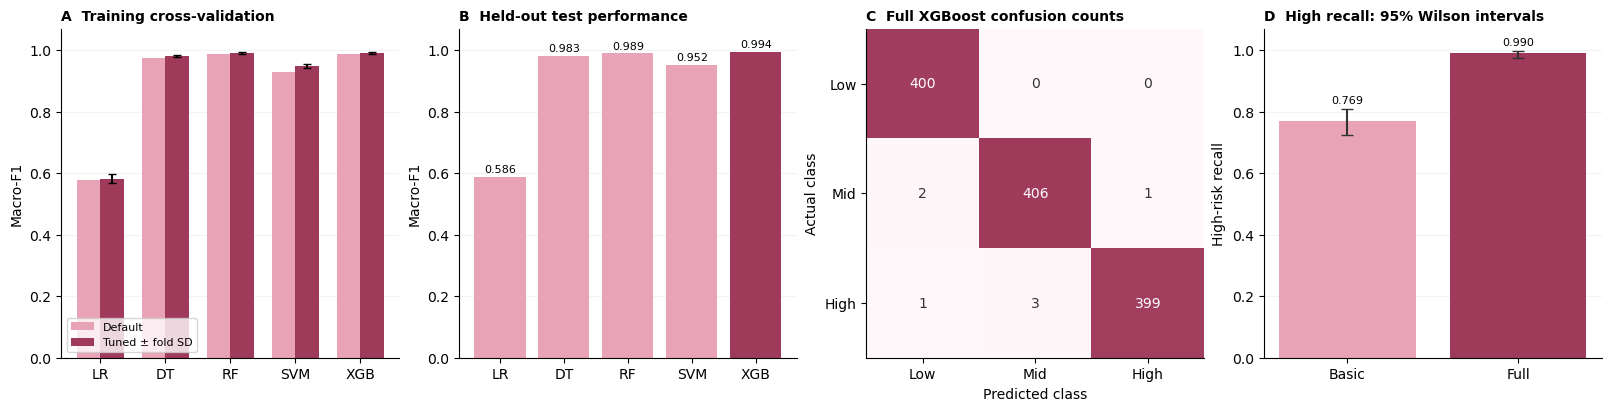

Đã vẽ và lưu đủ bốn panel có dữ liệu.
/Users/hgianee/Downloads/Maternal health risk data 2/output/report_final_checks/figures/F03_model_benchmark.pdf


In [49]:
from pathlib import Path
from io import BytesIO

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Đọc lại bảng benchmark đã chốt, không train model.
benchmark_folder = BASE / "section_4_1_verified"

cv_plot = pd.read_csv(
    benchmark_folder / "table_5_hyperparameter_tuning.csv"
)
test_plot = pd.read_csv(
    benchmark_folder / "table_6_final_test.csv"
)

order = ["LR", "DT", "RF", "SVM", "XGB"]

assert cv_plot.Model.is_unique
assert test_plot.Model.is_unique

cv_plot = (
    cv_plot.set_index("Model").loc[order].reset_index()
)
test_plot = (
    test_plot.set_index("Model").loc[order].reset_index()
)

cm_plot = confusion_matrix(
    y, pf.argmax(axis=1), labels=[0, 1, 2]
)

assert np.array_equal(
    cm_plot,
    np.array([[400, 0, 0], [2, 406, 1], [1, 3, 399]])
), "Full model không khớp baseline."

detection = (
    basic_full.set_index("Model")
    .loc[["Basic", "Full"]]
    .reset_index()
)

# Dùng tên biến riêng, không phụ thuộc fig/ax của các cell trước.
benchmark_fig, benchmark_axes = plt.subplots(
    1, 4,
    figsize=(16, 4),
    constrained_layout=True
)

a, b, c, d = benchmark_axes

light = "#E9A3B7"
dark = "#9F3A5B"

# A — Training cross-validation
x = np.arange(len(order))

a.bar(
    x - 0.18,
    cv_plot.Default_Macro_F1,
    width=0.36,
    color=light,
    label="Default"
)
a.bar(
    x + 0.18,
    cv_plot.Tuned_Macro_F1,
    width=0.36,
    yerr=cv_plot.Tuned_SD,
    capsize=3,
    color=dark,
    label="Tuned ± fold SD"
)
a.set_xticks(x)
a.set_xticklabels(order)
a.set_ylim(0, 1.07)
a.set_ylabel("Macro-F1")
a.set_title(
    "A  Training cross-validation",
    loc="left", fontsize=10, fontweight="bold"
)
a.legend(fontsize=8)

# B — Test Macro-F1
b.bar(
    order,
    test_plot.Macro_F1,
    color=[light, light, light, light, dark]
)
b.set_ylim(0, 1.07)
b.set_ylabel("Macro-F1")
b.set_title(
    "B  Held-out test performance",
    loc="left", fontsize=10, fontweight="bold"
)

for i, value in enumerate(test_plot.Macro_F1):
    b.text(
        i, value + 0.015,
        f"{value:.3f}",
        ha="center", fontsize=8
    )

# C — Confusion matrix
c.imshow(
    cm_plot,
    cmap=PINK_CMAP,
    aspect="auto",
    vmin=0,
    vmax=cm_plot.max()
)
c.set_xticks([0, 1, 2])
c.set_xticklabels(LABELS)
c.set_yticks([0, 1, 2])
c.set_yticklabels(LABELS)
c.set_xlabel("Predicted class")
c.set_ylabel("Actual class")
c.set_title(
    "C  Full XGBoost confusion counts",
    loc="left", fontsize=10, fontweight="bold"
)

for i, j in np.ndindex(cm_plot.shape):
    c.text(
        j, i, str(cm_plot[i, j]),
        ha="center", va="center",
        color="white" if cm_plot[i, j] > 200 else "#333333",
        fontsize=10
    )

# D — High recall with Wilson intervals
recall = detection.High_Recall.to_numpy()
lower = detection.Recall_Lower.to_numpy()
upper = detection.Recall_Upper.to_numpy()

d.bar(
    ["Basic", "Full"],
    recall,
    color=[light, dark]
)
d.errorbar(
    [0, 1],
    recall,
    yerr=np.vstack([recall - lower, upper - recall]),
    fmt="none",
    ecolor="#333333",
    capsize=4
)
d.set_ylim(0, 1.07)
d.set_ylabel("High-risk recall")
d.set_title(
    "D  High recall: 95% Wilson intervals",
    loc="left", fontsize=10, fontweight="bold"
)

for i, value in enumerate(recall):
    d.text(
        i, upper[i] + 0.02,
        f"{value:.3f}",
        ha="center", fontsize=8
    )

for axis in [a, b, d]:
    axis.grid(axis="y", alpha=0.15)
    axis.set_axisbelow(True)

# Kiểm tra cả bốn panel có dữ liệu trên đúng figure.
assert all(
    axis.figure is benchmark_fig
    for axis in benchmark_axes
)
assert len(a.patches) == 10
assert len(b.patches) == 5
assert len(c.images) == 1
assert len(d.patches) == 2

# Lưu trực tiếp figure vừa vẽ.
figure_folder = Path(FIG)
figure_folder.mkdir(parents=True, exist_ok=True)

for extension in ["pdf", "png", "svg"]:
    buffer = BytesIO()
    benchmark_fig.savefig(
        buffer,
        format=extension,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )
    output_path = (
        figure_folder / f"F03_model_benchmark.{extension}"
    )
    output_path.write_bytes(buffer.getvalue())

plt.show()
plt.close(benchmark_fig)

print("Đã vẽ và lưu đủ bốn panel có dữ liệu.")
print(figure_folder / "F03_model_benchmark.pdf")

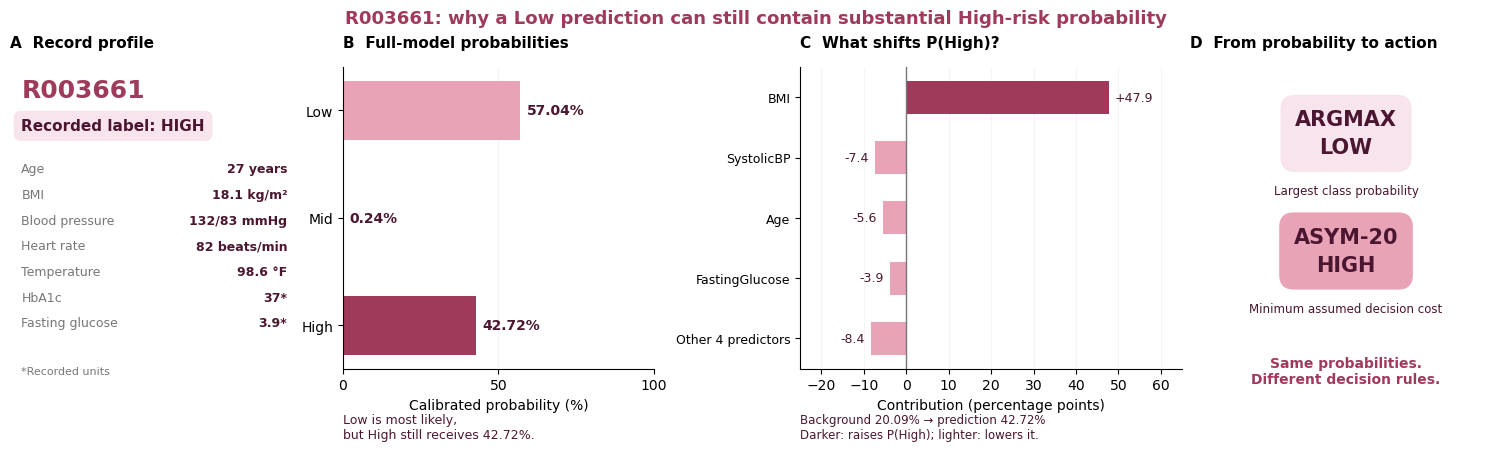

Đã lưu: /Users/hgianee/Downloads/Maternal health risk data 2/output/report_final_checks/figures/F05_patient_R003661.pdf


In [50]:
import numpy as np
import matplotlib.pyplot as plt
from io import BytesIO

CASE_ID = "R003661"

positions = np.flatnonzero(ids == CASE_ID)
assert len(positions) == 1
position = int(positions[0])

patient_record = test.iloc[position]
patient_probability = pf[position]

assert local_case.iloc[0]["row_id"] == CASE_ID
assert np.isclose(
    local_base + np.sum(local_values),
    patient_probability[2],
    atol=1e-5,
    rtol=0
)

LIGHT = "#E9A3B7"
MID = "#D86A8A"
DARK = "#9F3A5B"
PALE = "#F8E4EC"
TEXT = "#4B1730"
GRAY = "#777777"

patient_fig, patient_axes = plt.subplots(
    1, 4,
    figsize=(15, 4.4),
    constrained_layout=True,
    gridspec_kw={"width_ratios": [1, 1.1, 1.35, 1.1]}
)

profile_ax, probability_ax, shap_ax, action_ax = patient_axes


def heading(axis, letter, heading_text):
    axis.set_title(
        f"{letter}  {heading_text}",
        loc="left",
        fontsize=11,
        fontweight="bold",
        pad=14
    )


# -------------------------------------------------
# A. Hồ sơ: trình bày thành card, không có trục tọa độ
# -------------------------------------------------
profile_ax.axis("off")
heading(profile_ax, "A", "Record profile")

profile_ax.text(
    0.04, 0.90,
    CASE_ID,
    transform=profile_ax.transAxes,
    fontsize=18,
    fontweight="bold",
    color=DARK
)

profile_ax.text(
    0.04, 0.79,
    "Recorded label: HIGH",
    transform=profile_ax.transAxes,
    fontsize=11,
    fontweight="bold",
    color=TEXT,
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor=PALE,
        edgecolor="none"
    )
)

profile_lines = [
    ("Age", f"{patient_record['Age']:g} years"),
    ("BMI", f"{patient_record['BMI']:g} kg/m²"),
    (
        "Blood pressure",
        f"{patient_record['SystolicBP']:g}/"
        f"{patient_record['DiastolicBP']:g} mmHg"
    ),
    ("Heart rate", f"{patient_record['HeartRate']:g} beats/min"),
    ("Temperature", f"{patient_record['BodyTemp']:g} °F"),
    ("HbA1c", f"{patient_record['HbA1c']:g}*"),
    ("Fasting glucose", f"{patient_record['FastingGlucose']:g}*"),
]

for i, (label, value) in enumerate(profile_lines):
    yy = 0.65 - i * 0.085

    profile_ax.text(
        0.04, yy, label,
        transform=profile_ax.transAxes,
        fontsize=9, color=GRAY
    )
    profile_ax.text(
        0.98, yy, value,
        transform=profile_ax.transAxes,
        fontsize=9, color=TEXT,
        ha="right", fontweight="bold"
    )

profile_ax.text(
    0.04, -0.02,
    "*Recorded units",
    transform=profile_ax.transAxes,
    fontsize=8, color=GRAY
)


# -------------------------------------------------
# B. Full model: ba xác suất đọc trực tiếp
# -------------------------------------------------
heading(probability_ax, "B", "Full-model probabilities")

probability_ax.barh(
    np.arange(3),
    patient_probability * 100,
    color=[LIGHT, MID, DARK],
    height=0.55
)

probability_ax.set_yticks(np.arange(3))
probability_ax.set_yticklabels(LABELS)
probability_ax.invert_yaxis()
probability_ax.set_xlim(0, 100)
probability_ax.set_xticks([0, 50, 100])
probability_ax.set_xlabel("Calibrated probability (%)")
probability_ax.grid(axis="x", alpha=0.12)
probability_ax.set_axisbelow(True)

for i, value in enumerate(patient_probability):
    probability_ax.text(
        value * 100 + 2,
        i,
        f"{value:.2%}",
        va="center",
        fontsize=10,
        fontweight="bold",
        color=TEXT
    )

probability_ax.text(
    0, -0.23,
    "Low is most likely,\n"
    "but High still receives 42.72%.",
    transform=probability_ax.transAxes,
    fontsize=9, color=TEXT
)


# -------------------------------------------------
# C. SHAP: top 4 + tổng có dấu của phần còn lại
# -------------------------------------------------
heading(shap_ax, "C", "What shifts P(High)?")

contributions = np.asarray(local_values, dtype=float)
top_indices = np.argsort(-np.abs(contributions))[:4]
remaining = np.setdiff1d(
    np.arange(len(FULL)), top_indices
)

shap_labels = [
    FULL[i] for i in top_indices
] + ["Other 4 predictors"]

shap_values = np.concatenate([
    contributions[top_indices],
    [contributions[remaining].sum()]
])

shap_ax.barh(
    np.arange(len(shap_values)),
    shap_values * 100,
    color=[
        DARK if value >= 0 else LIGHT
        for value in shap_values
    ],
    height=0.55
)

shap_ax.set_yticks(np.arange(len(shap_labels)))
shap_ax.set_yticklabels(shap_labels, fontsize=9)
shap_ax.invert_yaxis()
shap_ax.axvline(0, color=GRAY, linewidth=1)
shap_ax.set_xlim(-25, 65)
shap_ax.set_xlabel("Contribution (percentage points)")
shap_ax.grid(axis="x", alpha=0.12)
shap_ax.set_axisbelow(True)

for i, value in enumerate(shap_values * 100):
    shap_ax.text(
        value + (1.3 if value >= 0 else -1.3),
        i,
        f"{value:+.1f}",
        ha="left" if value >= 0 else "right",
        va="center",
        fontsize=9,
        color=TEXT
    )

shap_ax.text(
    0, -0.23,
    f"Background {local_base:.2%}"
    f" → prediction {patient_probability[2]:.2%}\n"
    "Darker: raises P(High); lighter: lowers it.",
    transform=shap_ax.transAxes,
    fontsize=8.5,
    color=TEXT
)


# -------------------------------------------------
# D. Hai quy tắc cho hai hành động khác nhau
# -------------------------------------------------
action_ax.axis("off")
heading(action_ax, "D", "From probability to action")

cards = [
    (
        0.78,
        "ARGMAX",
        "LOW",
        "Largest class probability",
        PALE
    ),
    (
        0.39,
        "ASYM-20",
        "HIGH",
        "Minimum assumed decision cost",
        LIGHT
    ),
]

for yy, rule, result, explanation, background in cards:
    action_ax.text(
        0.5, yy,
        f"{rule}\n{result}",
        transform=action_ax.transAxes,
        ha="center", va="center",
        fontsize=15,
        fontweight="bold",
        color=TEXT,
        linespacing=1.5,
        bbox=dict(
            boxstyle="round,pad=0.7",
            facecolor=background,
            edgecolor="none"
        )
    )

    action_ax.text(
        0.5, yy - 0.19,
        explanation,
        transform=action_ax.transAxes,
        ha="center", va="center",
        fontsize=8.5, color=TEXT
    )

action_ax.text(
    0.5, -0.05,
    "Same probabilities.\n"
    "Different decision rules.",
    transform=action_ax.transAxes,
    ha="center", fontsize=10,
    fontweight="bold", color=DARK
)

patient_fig.suptitle(
    "R003661: why a Low prediction can still contain "
    "substantial High-risk probability",
    fontsize=13,
    fontweight="bold",
    color=DARK
)

# Lưu đúng figure này, ghi đè bản bệnh nhân trước.
for extension in ["pdf", "png", "svg"]:
    buffer = BytesIO()
    patient_fig.savefig(
        buffer,
        format=extension,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    output_path = FIG / f"F05_patient_R003661.{extension}"
    output_path.write_bytes(buffer.getvalue())

plt.show()
plt.close(patient_fig)

print("Đã lưu:", FIG / "F05_patient_R003661.pdf")